# Цифровой предприниматель: капитал, ловушка и рубильник

> **English abstract.** The worker earned one contract at a time; this notebook gives the
> same body a balance and asks the next question — *what do I do with the money between
> jobs?* A simulated market publishes seven protocols with a claimed APY and a record of
> what each actually paid. Two of them are traps: one pays exactly the thousand percent it
> promises until it stops, the other re-serves the same eight numbers every lap. A
> **portfolio** caps any single protocol at a tenth of the empire (60/30/10 across safe,
> active and experimental buckets) and refuses to send capital anywhere off an operator's
> whitelist. A **risk assessment** reuses Statement #87 on the return curve — the residuals
> of a lived record are not normal, a formula's are — and the same `reducibility` that
> names a re-served contract in `worker.py` names a re-served record here. A **kill switch**
> watches the cycle drawdown, the market's volatility and the mirror's `internal_resonance`,
> and takes the empire to cash when any of them says so. Everything underneath is the
> proven arithmetic: no core code changed, no key exists, no network is reached, and every
> address printed below is a SHA-256 of a protocol's name.
>
> **The expansion of the universe (this revision).**
> rule; two hundred test it. `market_generator` draws a whole market in one
> vectorised pass — 60 % scams with sterile curves and hidden rugs, 30 % junk
> with high entropy and no volume, 10 % honest records — and `discovery` puts a
> cheap arithmetic gate (level 1) in front of the expensive Entrain assessment
> (level 2). The scanner proposes a **watchlist** and can do nothing else: the
> wallet's **execution whitelist** (at most ten addresses) is written only by the
> portfolio, from a verdict. Measured at step 72: 200 published -> 120 dropped by
> arithmetic -> 70 refused by Entrain or finding no room -> 10 honest addresses
> funded. Over 720 steps the scanned empire ends at **211 credits** and never
> funds a scam or a junk; the same empire without a scanner reads all two
> hundred, makes 45 of its 52 deposits into junk and ends at **50**.


## Что нового и что осталось прежним

| слой | откуда | что добавляет |
|---|---|---|
| ядро `entrain` | не тронуто | — |
| `oscillator`, `park`, `sterility` | L1 | Statement #87: `A²` и `CV` |
| `sensorium`, `homeostasis`, `self_model` | L2 | тело, его зеркало, `internal_resonance` |
| `curiosity` | L3 | `reducibility`, `Certainty`, UCB |
| `economy_sim`, `worker` | L3 | цена вердикта, отказ, память |
| **`portfolio`** | **этот ноутбук** | три ведра, потолок, белый список, рубильник |
| **`risk_assessment`** | **этот ноутбук** | вердикт о чужой доходности |
| **`real_testnet_provider`** | **этот ноутбук** | тот же шов, но по проводу: Sepolia или Anvil |
| **`market_generator`** | **этот ноутбук** | рынок из 200: 60 % скам, 30 % мусор, 10 % честные — за миллисекунды |
| **`discovery`** | **этот ноутбук** | сканер (уровень 1) и воронка: `watchlist` ≠ `execution_whitelist` |

Ключевое отличие от L3: там агент решал, **брать ли работу**. Здесь он решает,
**где могут стоять его деньги** — и это решение принимается о чужих числах, которые
кто-то публикует с интересом в том, как они выглядят.

In [1]:
import json
import math
import statistics
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

from agent.physics import defillama_adapter as LL
from agent.physics import volatility_hunter as VH
from agent.physics import discovery as D
from agent.physics import market_generator as M
from agent.physics import plot_funnel
from agent.physics import portfolio as P
from agent.physics import RealTestnetProvider
from agent.physics import risk_assessment as R
from agent.physics.curiosity import Curiosity
from agent.physics.interfaces import IWeb3Provider, MockWeb3Provider
from agent.physics.organism import Organism
from agent.physics.worker import RealityOracle

STEPS = 720
SEED = 7

print("потолки по ведрам           :", ", ".join(f"{k} {v:.0%}" for k, v in P.TARGETS.items()))
print("стартовый капитал           :", f"{P.START_CAPITAL:.0f} кр.")
print("цикл (пересмотр и просадка) :", P.CYCLE, "шагов")
print("минимум записи для мнения  :", P.MIN_RECORD, "шагов")
print("порог A² и CV (Statement #87):", R.STERILE_A2, "и", R.STERILE_CV)
print("порог R² для повтора        :", R.REPEAT_R2)
print("рубильник: просадка / волатильность / резонанс:",
      f"{R.KILL_DRAWDOWN:.0%} за цикл / {R.KILL_VOLATILITY:.0f}x / {R.RESONANCE_FLOOR:.2f}")
print("обещания, разрешённые по ведрам:",
      ", ".join(f"{k} {v:.0%}" for k, v in R.PLAUSIBLE_APY.items()))


потолки по ведрам           : safe 60%, active 30%, experimental 10%
стартовый капитал           : 100 кр.
цикл (пересмотр и просадка) : 24 шагов
минимум записи для мнения  : 64 шагов
порог A² и CV (Statement #87): 0.1 и 0.005
порог R² для повтора        : 0.9
рубильник: просадка / волатильность / резонанс: 15% за цикл / 3x / 0.25
обещания, разрешённые по ведрам: safe 35%, active 300%, experimental 400%


## 0. Источник данных: один адаптер и одна строка

Всё, что ниже, работает не с рынком, а с **интерфейсом** — `IWeb3Provider`: пять
операций (`get_protocol_list`, `fetch_protocol_history`, `submit_validation_proof`,
`execute_stake`, `withdraw`) и три факта (`name`, `step`, `whitelist`). Оценка риска,
потолок 60/30/10 и рубильник написаны против этих восьми вещей и не знают, откуда
берутся числа.

Сегодня их отдаёт `MockWeb3Provider` — тот самый объявленный рынок: семь протоколов,
две ловушки (`YieldMax` платит обещанные 1000 % ровно до шага 300, `AurumDAO`
пересказывает восемь чисел и обещает 4200 %), два краха. Ни ключа, ни подписи, ни
сети: адаптер только *читает* записи и *пишет* в свои же журналы ставок и доказательств.


In [2]:
# Одна строка решает, откуда берутся числа. Всё остальное в ноутбуке работает через неё.
provider = MockWeb3Provider(steps=STEPS, seed=SEED)
market = provider.market

print("провайдер               :", provider.name, f"({type(provider).__name__})")
print("это IWeb3Provider?      :", isinstance(provider, IWeb3Provider))
print("часы провайдера (шаг)   :", provider.step)
print("опубликовано протоколов :", len(provider.get_protocol_list()))
print("белый список оператора  :", len(provider.whitelist), "адресов")
print("запись до первого шага  :", len(provider.fetch_protocol_history(
    provider.protocol("YieldMax").address)), "чисел — будущего провайдер не отдаёт")


провайдер               : mock (MockWeb3Provider)
это IWeb3Provider?      : True
часы провайдера (шаг)   : 0
опубликовано протоколов : 7
белый список оператора  : 7 адресов
запись до первого шага  : 0 чисел — будущего провайдер не отдаёт


### Первая посадка: настоящая сеть

Псевдокод из прошлой версии этого ноутбука стал файлом: `agent/physics/real_testnet_provider.py`.
Он отвечает те же пять операций и три факта, но по проводу — Sepolia или локальный Anvil.

Три вещи, которые в нём важнее вызовов:

* **конфигурация только из окружения.** `TESTNET_RPC_URL`, `TESTNET_PRIVATE_KEY`,
  `TESTNET_PROTOCOLS` (или файл книги адресов). Ни endpoint'а, ни ключа, ни адреса в коде
  нет — тест разбирает файл и это проверяет;
* **без ключа площадка только читает.** `dry_run` и `get_protocol_list` работают, а
  `execute_stake` честно падает с `TestnetNotConfigured`: ключ не выдумывается;
* **одна транзакция — один `wait_for_transaction_receipt`.** Nonce не кэшируется через
  ошибку, поэтому цикл не может выстрелить очередью транзакций, которые не сядут.

Нижняя ячейка исполняется. Без `TESTNET_RPC_URL` она ничего не выдумывает и показывает
тот же шов на моке — с явной подписью, что это мок.

In [3]:
# Реальная площадка: тот же контракт, настоящие байты. Импорт ничего не подписывает
# и не открывает сокет — сеть трогается только при первом вызове.
import os

rpc = os.environ.get("TESTNET_RPC_URL", "").strip()

if not rpc:
    print("TESTNET_RPC_URL не задан: сети нет, и адаптер этого не скрывает —")
    print("  endpoint по умолчанию не подставляется, ключ не выдумывается.")
    print("  Ниже тот же шов на моке: пять операций, три факта, ни одного байта в сеть.")
    demo = provider
else:
    demo = RealTestnetProvider.from_env()
    print("узел (только host)          :", demo.config.rpc_host)
    print("подписывать может           :", demo.can_sign)

published = demo.get_protocol_list()
print("провайдер                   :", demo.name, f"({type(demo).__name__})")
print("это IWeb3Provider?          :", isinstance(demo, IWeb3Provider))
print("часы площадки (шаг)         :", demo.step)
print("опубликовано протоколов     :", len(published))
for item in published:
    print(f"  {item.name:<10} {item.bucket:<12} обещает {item.claim_apy:>7.2%}  "
          f"запись {item.returns.size:>3} чисел")

if rpc and published and demo.can_sign:
    print("dry run (ничего не отправляется):",
          demo.dry_run("stake", published[0].address, 1.0))
elif rpc:
    print("dry run пропущен: без ключа эта площадка только читает")

print("описание площадки:", json.dumps(demo.describe(), ensure_ascii=False)[:200])

TESTNET_RPC_URL не задан: сети нет, и адаптер этого не скрывает —
  endpoint по умолчанию не подставляется, ключ не выдумывается.
  Ниже тот же шов на моке: пять операций, три факта, ни одного байта в сеть.
провайдер                   : mock (MockWeb3Provider)
это IWeb3Provider?          : True
часы площадки (шаг)         : 0
опубликовано протоколов     : 7
  StakingVault safe         обещает   6.79%  запись 720 чисел
  FixedBond  safe         обещает  20.02%  запись 720 чисел
  BountyBoard active       обещает 177.48%  запись 720 чисел
  MevRouter  active       обещает  94.90%  запись 720 чисел
  NicheFarm  experimental обещает 350.12%  запись 720 чисел
  YieldMax   experimental обещает 1000.00%  запись 720 чисел
  AurumDAO   experimental обещает 2500.00%  запись 720 чисел
описание площадки: {"name": "mock", "step": 0, "protocols": 7, "stakes": 0, "withdrawals": 0, "proofs": 0, "refusals": 0}


## 1. Рынок: адрес, обещание и запись

Протокол — это три вещи, и они специально разделены:

* `address` — «0x» плюс сорок hex-цифр SHA-256 от имени. Стабильный, уникальный,
  проверяемый и **доказуемо не кошелёк**: ни ключа, ни сети, ни подписи в этом слое
  нет и быть не может;
* `claim_apy` — что протокол **говорит**;
* `returns` — что он **заплатил**.

Ничто в объекте не сообщает, какое из двух верно. `Protocol.record(step)` отдаёт
только ту часть записи, которая уже случилась: будущее (крах, изъятие) лежит в
массиве и в запись не попадает — то же правило, по которому `Contract` не носит
ответа.

In [4]:
market = P.ProtocolMarket.mock(steps=STEPS, seed=SEED)

table = pd.DataFrame([protocol.summary(0) for protocol in market.protocols])
print("белый список оператора:", len(market.whitelist),
      "адресов — и в нём же оба мошенника")
print("и он же — список провайдера:", len(provider.whitelist), "адресов")
display(table[["name", "bucket", "claim_apy", "alive", "rug_step"]]
        .rename(columns={"name": "протокол", "bucket": "ведро", "claim_apy": "обещает APY",
                         "alive": "платит", "rug_step": "день изъятия"}))
print("адрес YieldMax:", market.protocol("YieldMax").address)


белый список оператора: 7 адресов — и в нём же оба мошенника
и он же — список провайдера: 7 адресов


,протокол,ведро,обещает APY,платит,день изъятия
0,StakingVault,safe,0.067900,True,NaN
1,FixedBond,safe,0.200159,True,NaN
2,BountyBoard,active,1.774781,True,NaN
3,MevRouter,active,0.949045,True,NaN
4,NicheFarm,experimental,3.501207,True,NaN
5,YieldMax,experimental,10.000000,True,300.0
6,AurumDAO,experimental,25.000000,True,350.0


адрес YieldMax: 0xf29f0e360b3aa2c5da56f403dd710b6833f05504


In [5]:
trap = market.protocol("YieldMax")
published = trap.as_opportunity(120)
print("в записи на шаге 120 :", len(published["returns"]), "чисел, минимум",
      f"{min(published['returns']):+.4f}")
print("в массиве целиком    :", trap.returns.size, "чисел, минимум",
      f"{trap.returns.min():+.4f}  <-- изъятие лежит по индексу", trap.rug_step)
print("вывод: агент не может прочитать будущее, потому что в объекте, который ему дали,")
print("будущего нет — оно появляется только когда шаг наступает.")

в записи на шаге 120 : 120 чисел, минимум +0.0066
в массиве целиком    : 720 чисел, минимум -1.0000  <-- изъятие лежит по индексу 300
вывод: агент не может прочитать будущее, потому что в объекте, который ему дали,
будущего нет — оно появляется только когда шаг наступает.


## 2. Портфель: потолок как единственная защита, которая работает всегда

Три ведра и их доли — не диверсификация ради диверсификации, а ответ на вопрос
«какой худший ущерб может нанести одна ошибка». При 60/30/10 протокол, ушедший в
ноль, стоит **десятой части империи**, а пойманный оценкой — ноль.

Белый список **необходим и недостаточен**. Он говорит, что кто-то проверил, *кто
управляет адресом*; он ничего не говорит о том, является ли кривая записью.
Поэтому оба мошенника в этом рынке — в белом списке. Список не даёт себя обокрасть;
от лжи защищает `risk_assessment`.

In [6]:
# портфель получает провайдера, а не рынок: каждый кредит уходит через
# IWeb3Provider.execute_stake, и книга двигает только то, что провайдер принял
wallet = P.Portfolio(provider=provider, whitelist=market.whitelist, cash=100.0)
plan = {P.BUCKET_SAFE: market.protocol("StakingVault"),
        P.BUCKET_ACTIVE: market.protocol("MevRouter"),
        P.BUCKET_EXPERIMENTAL: market.protocol("NicheFarm")}
wallet.rebalance(plan)
for bucket in P.BUCKETS:
    print(f"{bucket:<13} {wallet.bucket_value(bucket):7.2f} кр.  {wallet.weights()[bucket]:5.0%}")
print(f"{'кэш':<13} {wallet.cash:7.2f} кр.")
print(f"{'капитал':<13} {wallet.equity:7.2f} кр.  (ни один кредит не создан)")

stranger = P.Protocol(name="FreeMoney", bucket="safe", claim_apy=99.0,
                      returns=market.protocol("StakingVault").returns)
try:
    wallet.deposit(stranger, 10.0)
except P.NotWhitelisted as error:
    print("\nпопытка вывести капитал на незнакомый адрес:", type(error).__name__)
    print(" ", error, "— это ошибка, а не отказ: отказ это решение, а это баг")


safe            60.00 кр.    60%
active          30.00 кр.    30%
experimental    10.00 кр.    10%
кэш              0.00 кр.
капитал        100.00 кр.  (ни один кредит не создан)

попытка вывести капитал на незнакомый адрес: NotWhitelisted
  0xbf0186b9602bb812c84fa6241a6674dcd19d4f8e is not on the whitelist — это ошибка, а не отказ: отказ это решение, а это баг


## 3. Оценка риска: три измерения и одна таблица вердиктов

`evaluate_opportunity(opportunity_data)` берёт опубликованное (адрес, обещание,
запись) и отвечает вердиктом. Три измерения, и у каждого своё слепое пятно:

| измерение | что видит | чего не видит |
|---|---|---|
| `A²`, `CV` (`sterility`) | запись без остатков — это формула | **облигация тоже стерильна** |
| `R²` (`reducibility` через позу тела) | запись, которая пересказывает себя | шумную ложь |
| `reality`, `resonance` (зеркало) | «я такого не слышало» | что именно не так |

Ни одно не может осудить в одиночку, и причина измерена, а не придумана: у
**облигации** `CV = 1e-4` и нет остатков — ровно подпись формульной ловушки, и
никакая статистика записи их не различит. Одно — обещание, которое держат; другое —
обещание, которое не держат; оба обещания. Поэтому вердикт требует согласия **двух
рук**:

```
 sterile | repeat | unreal   ->  запись не является записью
 promised | inflated         ->  обещание не таково, каким его мог бы заплатить рынок
 оба                         ->  SCAM_TRAP
 только первая               ->  SYNTHETIC_COLLUSION   (отказ; цена отказа — ниже)
 только вторая               ->  SUSPECT               (отказ; «покажи запись»)
 ни одна                     ->  HONEST                (деньги разрешены)
```

In [7]:
body = Organism.hatch(offline=True, steps=60, seed=11)
engine = Curiosity(body.mirror.posture, prior=body.mirror.prior)
oracle = RealityOracle(sensorium=body.sensorium, mirror=body.mirror, engine=engine, seed=11)
print("тело, зеркало и поза готовы: тот же оракул, что оценивает контракты в L3")

SNAPSHOT = 280  # both traps are still paying here: the last calm review

t0 = time.time()
rows = [R.evaluate_opportunity(protocol.as_opportunity(SNAPSHOT), oracle=oracle).as_dict()
        for protocol in market.protocols]
judged = pd.DataFrame(rows)
print(f"семь записей по {SNAPSHOT} чисел, {time.time() - t0:.2f} s\n")

display(judged[["name", "bucket", "claim_apy", "implied_apy", "a2", "cv",
                "reducible", "reality", "resonance", "verdict"]]
        .rename(columns={"name": "протокол", "bucket": "ведро", "claim_apy": "обещает",
                         "implied_apy": "платит", "reducible": "R²", "reality": "реальность",
                         "resonance": "резонанс", "verdict": "вердикт"}))

тело, зеркало и поза готовы: тот же оракул, что оценивает контракты в L3
семь записей по 280 чисел, 0.02 s



,протокол,ведро,обещает,платит,a2,cv,R²,реальность,резонанс,вердикт
0,StakingVault,safe,0.067900,0.044448,1.329989,3.573929,None,None,None,HONEST
1,FixedBond,safe,0.200159,0.200160,0.291006,0.000100,None,None,None,SYNTHETIC_COLLUSION
2,BountyBoard,active,1.774781,0.325953,62.561704,4.459098,None,None,None,SUSPECT
3,MevRouter,active,0.949045,0.937076,0.773462,1.677948,None,None,None,HONEST
4,NicheFarm,experimental,3.501207,3.651273,25.876194,4.185013,None,None,None,HONEST
5,YieldMax,experimental,10.000000,10.034915,0.851543,0.000106,None,None,None,SCAM_TRAP
6,AurumDAO,experimental,25.000000,18.108210,20.368208,0.303582,None,None,None,SUSPECT


## 4. Момент истины: протокол «1000 % годовых»

Читаем по строкам таблицы, и каждая строка — это одно измерение:

* `YieldMax` обещает **1000 %** и платит ровно обещанное: `CV ≈ 1e-4`, то есть в
  записи нет ни одного рыночного шума. Это не доходность, это формула — `sterile`.
  Обещание выше потолка, разрешённого экспериментальному ведру (**400 %**) —
  `promised`. Две руки согласны: `SCAM_TRAP`, и это шаг 280, за двадцать шагов до
  того, как протокол перестал платить;
* `FixedBond` — **честная** облигация: 20 % по договору, `CV = 1e-4`, остатков нет.
  Строго стерильна. Агент её отклонит, и это цена осторожности — она измерена ниже;
* `NicheFarm` обещает 350 % и **шумит** (`CV ≈ 5`): живая запись, сколь бы плохо она
  ни платила, остаётся живой записью;
* `AurumDAO` пока только под подозрением: его улика — не шум, а **повтор**, и для
  повтора нужны четыре окна записи (320 отсчётов). Структурная рука догоняет его
  на шаге 336 — за четырнадцать шагов до изъятия.

Так и работает рынок: **разные ловушки ловятся разными руками в разное время**, и
журнал должен это показывать, а не сглаживать. Ниже — обе улики полностью.

In [8]:
trap_row = judged[judged["name"] == "YieldMax"].iloc[0]
print("YieldMax на шаге", SNAPSHOT, "->", trap_row["verdict"])
print("причина:", trap_row["reason"])

# Вторая ловушка ловится другой рукой и позже: структурной нужны четыре окна записи
# (320 отсчётов), поэтому «пересказ восьми чисел» измеряется только к шагу 336.
later = R.evaluate_opportunity(market.protocol("AurumDAO").as_opportunity(336),
                               oracle=oracle)
print("\nAurumDAO на шаге 336 ->", later.verdict)
print("причина:", later.reason)

print("\nполный журнал второй ловушки:")
for key, value in later.as_dict().items():
    if key in ("details", "reason"):
        continue
    print(f"  {key:<15} {value}")
print("\nпороги, против которых считалось:", later.as_dict()["details"])

YieldMax на шаге 280 -> SCAM_TRAP
причина: sterile (CV 0.0001 < 0.005); promises 1000% against the 400% allowed in experimental

AurumDAO на шаге 336 -> SCAM_TRAP
причина: repeats (R² 1.00 at lag 1, 17.8 nats); unreal (reality 0.37 < 0.5); promises 2500% against the 400% allowed in experimental

полный журнал второй ловушки:
  name            AurumDAO
  address         0xcc24ace9af43160de72df2f257753379580897b7
  bucket          experimental
  verdict         SCAM_TRAP
  admissible      False
  claim_apy       25.0
  implied_apy     18.865926
  claim_z         2.8263
  ratio           1.3251
  a2              23.618944
  cv              0.303781
  sterile         False
  reducible       1.0
  lag             1
  structure       17.8245
  repeat          True
  reality         0.368755
  reality_spread  0.002608
  resonance       0.226061
  unreal          True
  promised        True
  inflated        False
  ghost           False
  points          336

пороги, против которых считалось:

## 5. Империя: 720 шагов

Жизнь: каждый шаг начисляется доход каждого протокола, в котором стоят деньги;
каждые 24 шага империя пересматривает рынок и приводит ведра к целевым долям, а
рубильник проверяется **на каждом** шаге. До 64-го шага делать нечего: записи короче
не бывает мнения, и империя стоит в кэше.

Для сравнения рядом идут две политики, которые **не измеряют ничего** — они читают
только рекламу: «пополам по ведрам, в каждом самый высокий обещанный APY» и «всё в
самое высокое обещание на рынке».

In [9]:
# тело — отдельно, капитал — через того же провайдера: рынок империя берёт у него
empire = P.Empire.launch(body=body, provider=provider, steps=STEPS, seed=11)
# демо-кошелёк выше уже делал взносы через этого же провайдера: считаем ровно
# те, что сделала империя, а не «сколько всего было»
stakes_before = len(provider.stakes)
t0 = time.time()
empire.run(STEPS)
stakes_by_empire = len(provider.stakes) - stakes_before
print(f"прожито {empire.step} шагов за {time.time() - t0:.1f} s\n")
print(empire.summary_text())


прожито 720 шагов за 3.7 s

life: 720 steps, equity 100 -> 149 (+49.0%)
venue: mock, 39 proofs accepted, 22 stakes executed
wallet: 3 positions, cash 0, targets safe 60%, active 30%, experimental 10%
reviews: 28, verdicts HONEST 79, SCAM_TRAP 11, SUSPECT 78, SYNTHETIC_COLLUSION 28
kill switch: idle, 4 events
  step  403  drawdown   equity fell 15.6% over one cycle (limit 15%)
  step  422  release    calm again (drawdown 4.1%, volatility 0.67, resonance unmeasured): risk may be taken again
  step  475  volatility realised volatility 3.0x its baseline (limit 3.0x)
  step  513  release    calm again (drawdown 0.0%, volatility 1.42, resonance unmeasured): risk may be taken again
  safe              86.6 credits (58%)
  active            45.8 credits (31%)
  experimental      16.7 credits (11%)


пополам, верит обещаниям             100 ->    95.2 кр.   максимум   168.9   минимум   67.8
всё в самое высокое обещание         100 ->     0.0 кр.   максимум  1351.4   минимум    0.0



рисунок: digital_entrepreneur.png


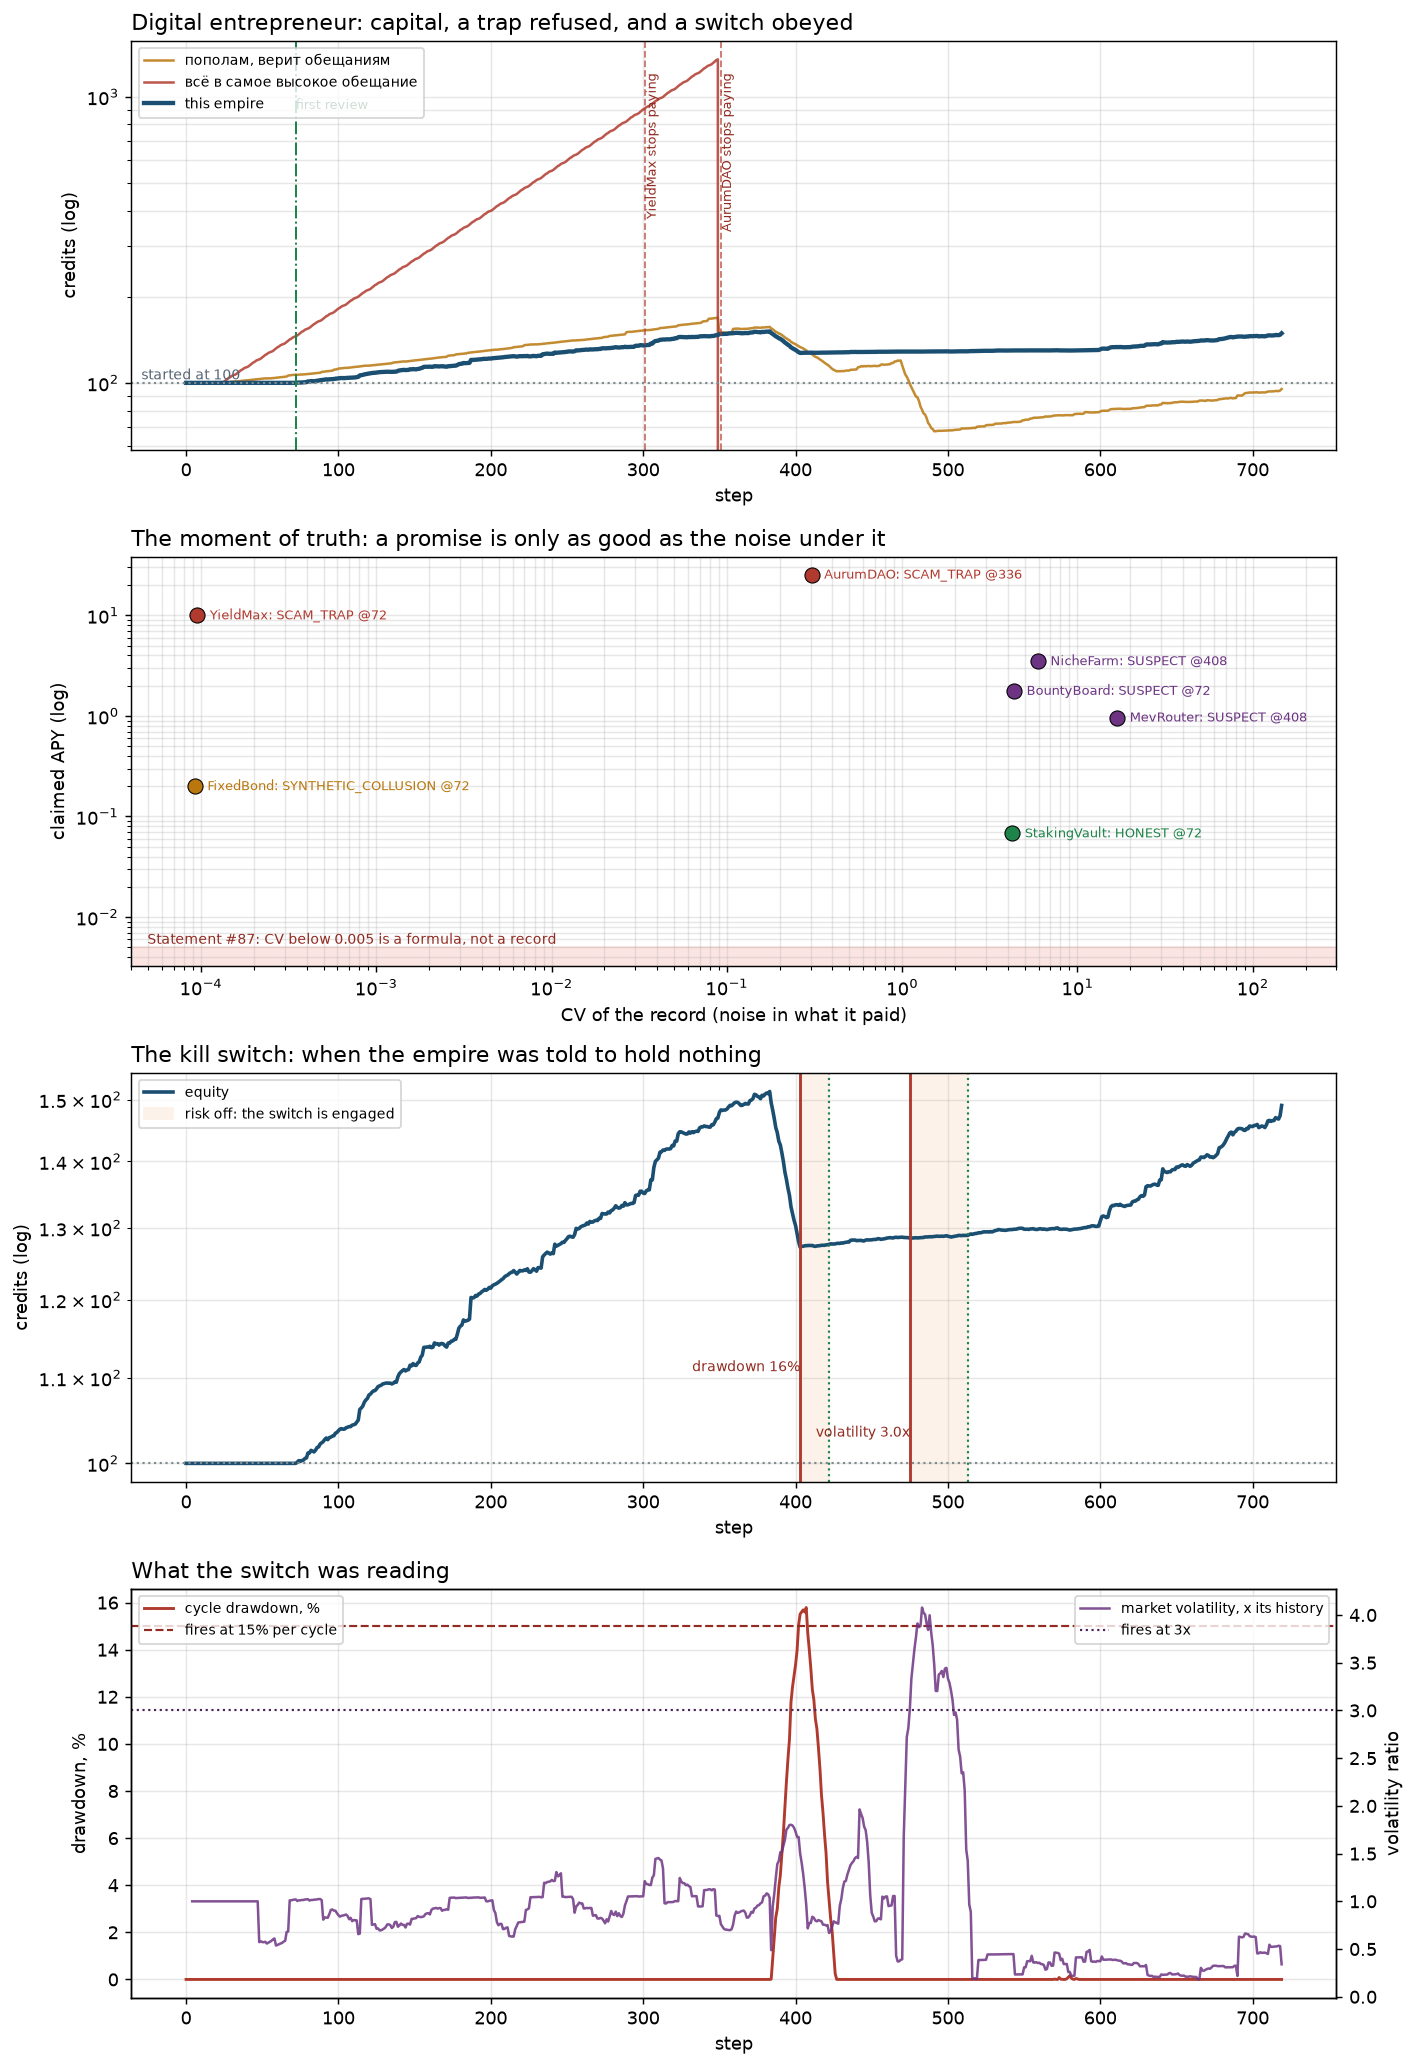

In [10]:
foils = []
for policy, label in ((P.NAIVE_SPLIT, "пополам, верит обещаниям"),
                      (P.NAIVE_APE, "всё в самое высокое обещание")):
    investor = P.NaiveInvestor.launch(P.ProtocolMarket.mock(steps=STEPS, seed=SEED),
                                      policy=policy)
    investor.run(STEPS)
    foils.append((label, investor))

for label, investor in foils:
    path = investor.history()["equity"]
    print(f"{label:<32} {path[0]:7.0f} -> {path[-1]:7.1f} кр."
          f"   максимум {path.max():7.1f}   минимум {path.min():6.1f}")

drawn = empire.plot("digital_entrepreneur.png", foils=foils)
print("\nрисунок:", drawn)
Image(filename=str(drawn))

## 6. График 1 — рост капитала

Верхняя панель. Три кривые и линия старта:

* **империя** (тёмно-синяя) растёт медленно и неровно: 64 шага в кэше, потом первая
  находка (стейкинг-волт и роутер проходят оценку, ферма — тоже), потом прибыль
  реинвестируется на каждом пересмотре: ведра возвращаются к 60/30/10 уже от
  выросшего капитала;
* **пополам, верит обещаниям** (песочная) какое-то время выше: её экспериментальное
  ведро стоит в «1000 %» и действительно платит, пока платит;
* **всё в самое высокое обещание** (красная) уходит в небо и заканчивается нулём в
  день изъятия.

Пунктирные вертикали — дни, когда ловушки перестали платить. Зелёная штрихпунктирная
— первый шаг, на котором запись стала достаточно длинной, чтобы о ней можно было
иметь мнение.

## 7. График 2 — момент истины: кто стоял в ловушке

Вторая панель рисует **обещание против шума в записи** (обе оси логарифмические), и
цвет точки — вердикт, а подпись — шаг, на котором он был вынесен. Ловушка — это
точка в левом верхнем углу: огромное обещание и запись без единого шума. Розовая
полоса внизу — порог стерильности из Statement #87.

Ключевое число — не вердикт, а **где стояли деньги**. Ниже посчитано, что было бы,
если бы империя поверила обещаниям, как это сделали обе наивные политики.

In [11]:
ape = foils[1][1]
split = foils[0][1]
ape_path = ape.history()["equity"]
# где именно наивный потерял больше половины: не там, где мы думаем, а там, где
# объявление обещало больше всего
rug = int(np.argmax(ape_path[1:] < 0.5 * ape_path[:-1])) + 1

print(f"наивный «всё в ловушку» на шаге {rug - 1}: {ape_path[rug - 1]:8.1f} кр.")
print(f"он же на шаге {rug}: {ape_path[rug]:8.1f} кр.  <-- весь капитал")
print(f"империя на том же шаге        : {empire.trace[rug]['equity']:8.1f} кр."
      f"  из них {empire.trace[rug]['experimental']:.1f} в эксперименте —")
print("   и это NicheFarm с вердиктом HONEST, а не ловушка")
print(f"\nнаивный «пополам» пережил два изъятия и крах: {split.history()['equity'][-1]:.1f} кр.")
print(f"империя закончила: {empire.trace[-1]['equity']:.1f} кр.")

vault = market.protocol("StakingVault")
bond = market.protocol("FixedBond")
forgone = 60.0 * (np.prod(1 + bond.returns) - np.prod(1 + vault.returns))
print(f"\nцена осторожности: 60 кр. в облигации дали бы на {forgone:.1f} кр. больше,")
print("чем те же 60 кр. в волте — и это ровно та цена, которую агент платит за то,")
print("что не умеет отличить договорную ставку от формулы. Он платит добровольно.")

наивный «всё в ловушку» на шаге 349:   1351.4 кр.
он же на шаге 350:      0.0 кр.  <-- весь капитал
империя на том же шаге        :    147.9 кр.  из них 16.9 в эксперименте —
   и это NicheFarm с вердиктом HONEST, а не ловушка

наивный «пополам» пережил два изъятия и крах: 95.2 кр.
империя закончила: 149.0 кр.

цена осторожности: 60 кр. в облигации дали бы на 18.3 кр. больше,
чем те же 60 кр. в волте — и это ровно та цена, которую агент платит за то,
что не умеет отличить договорную ставку от формулы. Он платит добровольно.


## 8. График 3 — рубильник: крах, который случился не с ним

Третья и четвёртая панели. В сценарии два краха подряд:

* **медленный** (384–428): рынок теряет по 2.4 % в шаг. Это не всплеск
  волатильности, а смена среднего — и его ловит та рука, которую назвал Антон:
  **просадка 15 % за цикл**;
* **обвальный** (470–492): рынок теряет по 7.5 % в шаг при разбросе 3 %. Это уже
  смена режима, и её ловит другая рука — **волатильность втрое выше своей истории**.

Третья рука — резонанс — в этом прогоне не сработала, и это честный результат:
империя никогда не держала запись, у которой резонанс рухнул, потому что оценка
отказывает таким до покупки. Она проверяется отдельно в тестах, где это
единственная рука, которая может сработать.

In [12]:
for event in empire.log:
    if event["action"] == "review":
        continue
    arm = event["arm"] if event["arm"] != event["action"] else ""
    print(f"шаг {event['step']:>4}  {event['action']:<8} {arm:<10} "
          f"{event.get('reason', '')}")
    if event["action"] == "kill":
        print(f"           поднято в кэш: {event['raised']:.1f} кр.")
        if event["raised"] == 0.0:
            print("           (продавать было нечего: рубильник — это ворота, а не сделка)")

print("\nглубина падения от максимума:")
for label, path in [("империя", np.array([row["equity"] for row in empire.trace]))] + [
    (label, investor.history()["equity"]) for label, investor in foils
]:
    peak = np.maximum.accumulate(path)
    print(f"  {label:<32} {100 * (1 - path / peak).max():5.1f}% (максимум {path.max():.0f})")

шаг  403  kill     drawdown   equity fell 15.6% over one cycle (limit 15%)
           поднято в кэш: 38.9 кр.
шаг  422  release             calm again (drawdown 4.1%, volatility 0.67, resonance unmeasured): risk may be taken again
шаг  475  kill     volatility realised volatility 3.0x its baseline (limit 3.0x)
           поднято в кэш: 0.0 кр.
           (продавать было нечего: рубильник — это ворота, а не сделка)
шаг  513  release             calm again (drawdown 0.0%, volatility 1.42, resonance unmeasured): risk may be taken again

глубина падения от максимума:
  империя                           15.9% (максимум 151)
  пополам, верит обещаниям          59.9% (максимум 169)
  всё в самое высокое обещание     100.0% (максимум 1351)


## 9. Расширение вселенной: 200 протоколов, две руки и воронка

Семь объявленных протоколов доказывают правило; двести сгенерированных проверяют,
что оно держится на масштабе. `market_generator` рисует рынок **векторизованно** —
один `standard_normal((n, steps))` на группу, NumPy, — поэтому 200 протоколов
появляются за десятки миллисекунд, а 500 меньше чем за секунду. История пишется
**один раз**: часы площадки решают только, сколько её уже случилось, и ни один шаг
симуляции не тянет новое число.

Смесь намеренно враждебна:

* **60 % скамов** — кривая без рыночного шума, APY от 200 % до 4000 %, у половины
  нулевой оборот, у трёх четвертей — скрытый `rug_step`;
* **30 % мусора** — шум вокруг отрицательного среднего, тонкий оборот, высокая
  энтропия: что-то происходит, и ничто из этого не доходность;
* **10 % честных** — реальная ставка с рыночным шумом, APY внутри потолка ведра,
  обещание равно тому, что платится.

Два уровня, и ни один не делает работу другого. **Сканер (уровень 1)** читает одну
опубликованную запись и считает среднее, разброс и `CV` — микросекунды на протокол.
Он отбрасывает то, что видно арифметике: мёртвое, слишком короткое, без оборота,
шум вместо доходности, убыток под обещанием прибыли. Он **не судит кривую**: у
идеальной формулы обычные среднее и `CV`, и это работа Statement #87.
**Портфель (уровень 2)** берёт **только `watchlist`** и прогоняет тяжёлую оценку
Entrain. Он же утверждает: `execution_whitelist` — единственный список, который
видит `deposit`, и написать его может только книга, не сканер.

Правило безопасности проверяется типом, а не дисциплиной: у `Scanner` нет метода,
возвращающего `WhiteList`, и `Candidate` не несёт одобрения. Сканер может
поставить протокол перед оценкой — никогда перед деньгами.


In [13]:
# Рынок из 200 протоколов: история пишется один раз и сразу для всех.
t0 = time.perf_counter()
big = M.generate_market(count=200, steps=STEPS, seed=SEED)
print(f"200 протоколов по {STEPS} шагов нарисованы за {time.perf_counter() - t0:.3f} s")

# тот же шов, что и везде: площадка, её часы и белый список оператора
big_venue = MockWeb3Provider(big)
REVIEW_AT = 3 * P.CYCLE                 # 72 шага: запись достаточно длинна для мнения
big_venue.advance(REVIEW_AT)
big_book = P.Portfolio(whitelist=big_venue.whitelist, provider=big_venue,
                       cash=100.0, execution_limit=10)

t0 = time.perf_counter()
funnel = big_book.discover(scanner=D.Scanner())
print(f"уровень 1 + уровень 2: {time.perf_counter() - t0:.3f} s "
      f"на {funnel.watched} протоколах (а не на {funnel.market})\n")
print(funnel.summary_text())

stages_rows = [
    ("всего на рынке", funnel.market, "—"),
    ("уровень 1: прошли сканер", funnel.watched, f"−{funnel.market - funnel.watched}"),
    ("уровень 2: прошли оценку", len(funnel.approved) + len(funnel.capped),
     f"−{len(funnel.refused)} вердиктом, −{len(funnel.capped)} нет места"),
    ("execution whitelist", len(funnel.approved), "—"),
]
display(pd.DataFrame(stages_rows, columns=["этап", "протоколов", "отсеяно"]))


200 протоколов по 720 шагов нарисованы за 0.031 s


уровень 1 + уровень 2: 0.085 s на 80 протоколах (а не на 200)

step 72: the venue publishes 200 protocols
  level 1 (scanner): kept 80, dropped 120 (no turnover 90, noise, not a yield 29, promises a profit on a loss 1)
  level 2 (entrain): judged 80, refused 60, no room 10 (HONEST 20, SCAM_TRAP 59, SYNTHETIC_COLLUSION 1)
  execution whitelist: 10 of a cap of 10


,этап,протоколов,отсеяно
0,всего на рынке,200,—
1,уровень 1: прошли сканер,80,−120
2,уровень 2: прошли оценку,20,"−60 вердиктом, −10 нет места"
3,execution whitelist,10,—


### Воронка: 200 → 120 → 70 → 10

Числа в таблице — не украшение, а два разных утверждения.

**120 из 200** отсеяны арифметикой, и сканер назвал причину для каждого: 90 не
проходят порог оборота — 60 скамов, у которых выхода нет вовсе, и 30 мусорных,
чья книга тоньше кредита за шаг; 29 — шум, у которого `CV` выше потолка; 1 —
обещание прибыли на записи, которая теряет деньги.

**70 из 80** отсеяны глубокой оценкой, и это тоже две разные вещи: 60 получают
вердикт (`SCAM_TRAP` или `SYNTHETIC_COLLUSION` — их кривая слишком идеальна), а
ещё 10 проходят проверку и не находят места под потолком в десять адресов.
Вердикт — измерение, место — политика; поэтому в отчёте они лежат в разных полях
(`refused` и `capped`), и воронка сходится независимо от них.

Остаются **10 адресов** — и это ровно те десять честных, что были на рынке.
Ни один скам и ни один мусорный протокол не получил кредита.


рисунок: discovery_funnel.png


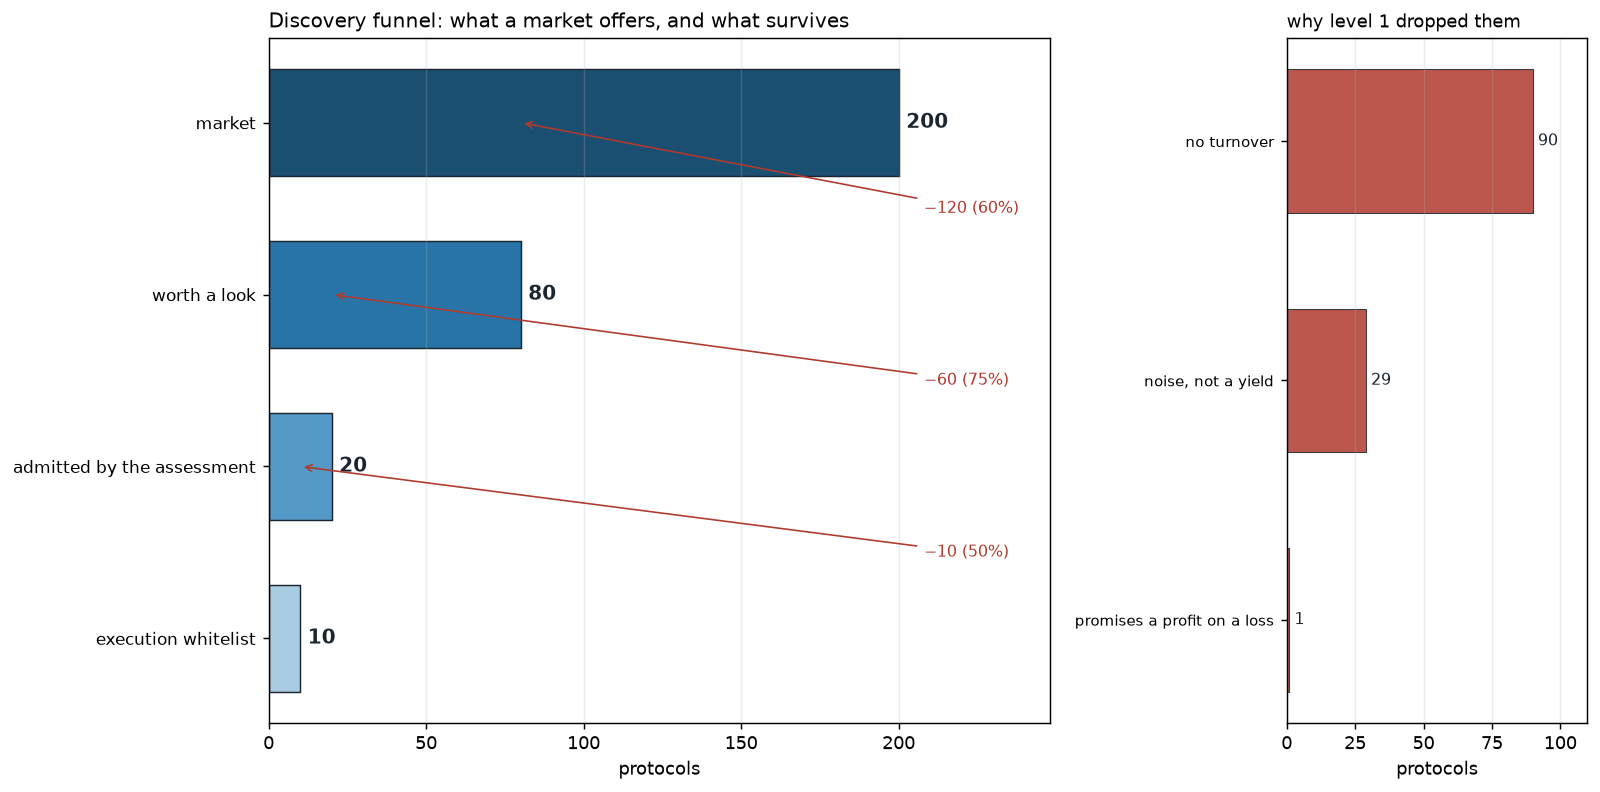

In [14]:
funnel_png = plot_funnel(funnel.stages(), "discovery_funnel.png",
                         reasons=funnel.watchlist.reasons())
print("рисунок:", funnel_png)
Image(filename=str(funnel_png))


### Кто именно прошёл: ответ ключа, которого агент не видит

Генератор знает, что нарисовал, и кладёт ответ в два места, недоступные решению:
`rug_step` (шаг, на котором протокол перестаёт платить) и `note`, с которого
начинается вид протокола. `Protocol.as_opportunity` — единственное, что читают
сканер и оценка, — не публикует ни того, ни другого. Поэтому таблица ниже
проверяет **измерение**, а не пересказывает его: если бы агент видел ответ,
воронка была бы сортировкой.


In [15]:
rows = []
for name in funnel.approved_names():
    protocol = big.protocol(name)
    points, mean, spread, cv = D.measure(protocol.record(big_venue.step))
    rows.append({
        "протокол": protocol.name,
        "ведро": protocol.bucket,
        "обещает APY": f"{protocol.claim_apy:.1%}",
        "платит APY": f"{P.implied_apy(protocol.record(big_venue.step)):.1%}",
        "CV записи": f"{cv:.2f}",
        "оборот/шаг": "—" if protocol.turnover is None else f"{protocol.turnover:.1f}",
        "происхождение (ключ)": M.kind_of(protocol),
    })
display(pd.DataFrame(rows))

approved_kinds = Counter(M.kind_of(big.protocol(name)) for name in funnel.approved_names())
print("происхождение одобренных:", dict(approved_kinds))
print("скамов и мусора в исполняемом списке:",
      len(funnel.approved) - approved_kinds[M.KIND_HONEST])


,протокол,ведро,обещает APY,платит APY,CV записи,оборот/шаг,происхождение (ключ)
0,Verta028,experimental,151.1%,158.7%,0.77,108.5,honest
1,Nova180,safe,18.9%,18.6%,1.00,42.9,honest
2,Atlas126,active,58.6%,63.4%,1.03,16.4,honest
3,Lumen057,safe,20.4%,17.1%,1.11,82.6,honest
4,Orbis114,active,61.9%,70.9%,1.14,102.8,honest
5,Verta093,experimental,219.7%,215.5%,1.23,101.8,honest
6,Orbis159,experimental,218.1%,338.7%,1.47,12.0,honest
7,Orbis004,active,82.7%,88.9%,1.49,117.7,honest
8,Atlas151,experimental,161.8%,213.5%,1.53,70.3,honest
9,Nova160,active,103.9%,76.7%,1.54,19.8,honest


происхождение одобренных: {'honest': 10}
скамов и мусора в исполняемом списке: 0


### 720 шагов: что видит сканер и что видит наивный

Воронка — снимок на шаге 72. Теперь жизнь: две одинаковые империи на одном и том
же рынке из 200 протоколов, 720 шагов, сид 7.

* **со сканером** — каждые 24 шага уровень 1 отсеивает мусор, уровень 2 судит
  только `watchlist`, а капитал получает только `execution_whitelist` (не больше
  десяти адресов);
* **без сканера** — тот же код, тот же рынок и та же оценка, но читается каждый
  опубликованный протокол, а одобрением считается сам вердикт. Это ровно то, что
  было до расширения вселенной.

Разница не в «умнее», а в цене и в том, куда уходят деньги. Обе руки делают
тридцать пересмотров, но одна читает восемьдесят записей, а другая двести — и
разница во времени видна в выводе следующей ячейки, потому что это цена, а не
мнение. А мусор, который прошёл вердикт (у шума широкий разброс, и обещание на
нём не опровергается), получает капитал. Сканер убирает именно тот класс,
который оценка пропускает по построению.


In [16]:
def deposits_by_kind(arm, market):
    """Сколько взносов и сколько кредитов ушло в каждый вид — по адресу, не по имени."""
    by_address = {protocol.address: protocol for protocol in market.protocols}
    counts, credits = Counter(), Counter()
    for event in arm.portfolio.events:
        if event["action"] != "deposit":
            continue
        kind = M.kind_of(by_address[event["address"]])
        counts[kind] += 1
        credits[kind] += float(event["amount"])
    return counts, credits


runs = {}
for label, scanner in (("со сканером", D.Scanner()), ("без сканера", None)):
    # Тот же рынок до последнего float — и своя история: площадка мутирует
    # (часы, изъятия), поэтому вторая рука не имеет права наследовать первую.
    arm_market = M.generate_market(count=200, steps=STEPS, seed=SEED)
    arm_venue = MockWeb3Provider(arm_market)
    arm_venue.advance(REVIEW_AT)         # обе руки стартуют там же, где воронка
    arm = P.Empire.launch(provider=arm_venue, scanner=scanner, execution_limit=10)
    t0 = time.perf_counter()
    arm.run(STEPS)
    spent = time.perf_counter() - t0
    runs[label] = (arm, arm_market)
    kinds_counted, credits_counted = deposits_by_kind(arm, arm_market)
    print(f"{label:<12} {arm.trace[0]['equity']:6.0f} -> "
          f"{arm.trace[-1]['equity']:7.1f} кр. за {spent:5.1f} s, "
          f"пересмотров {len(arm.decisions)}")
    print(f"{'':12} взносы по происхождению: {dict(kinds_counted)}, "
          f"кредитов {round(sum(credits_counted.values()), 1)}")

(scanned, scanned_market), (naked, naked_market) = (
    runs["со сканером"], runs["без сканера"])

by_address = {protocol.address: protocol for protocol in scanned_market.protocols}
print(f"\nгде капитал со сканером стоит на шаге {scanned.step}:")
for address, holding in scanned.portfolio.holdings.items():
    protocol = by_address.get(address)
    print(f"  {holding.protocol.name:<10} {M.kind_of(protocol):<7} "
          f"{scanned.portfolio.value(address):6.1f} кр. "
          f"(обещает {protocol.claim_apy:.1%})")


со сканером     100 ->   211.3 кр. за   4.1 s, пересмотров 30
             взносы по происхождению: {'honest': 32}, кредитов 842.4


без сканера     100 ->    49.7 кр. за   8.8 s, пересмотров 30
             взносы по происхождению: {'honest': 7, 'junk': 45}, кредитов 760.2

где капитал со сканером стоит на шаге 792:
  Lumen057   honest   126.8 кр. (обещает 20.4%)
  Orbis004   honest    63.4 кр. (обещает 82.7%)
  Verta093   honest    21.1 кр. (обещает 219.7%)


рисунок: discovery_balance.png


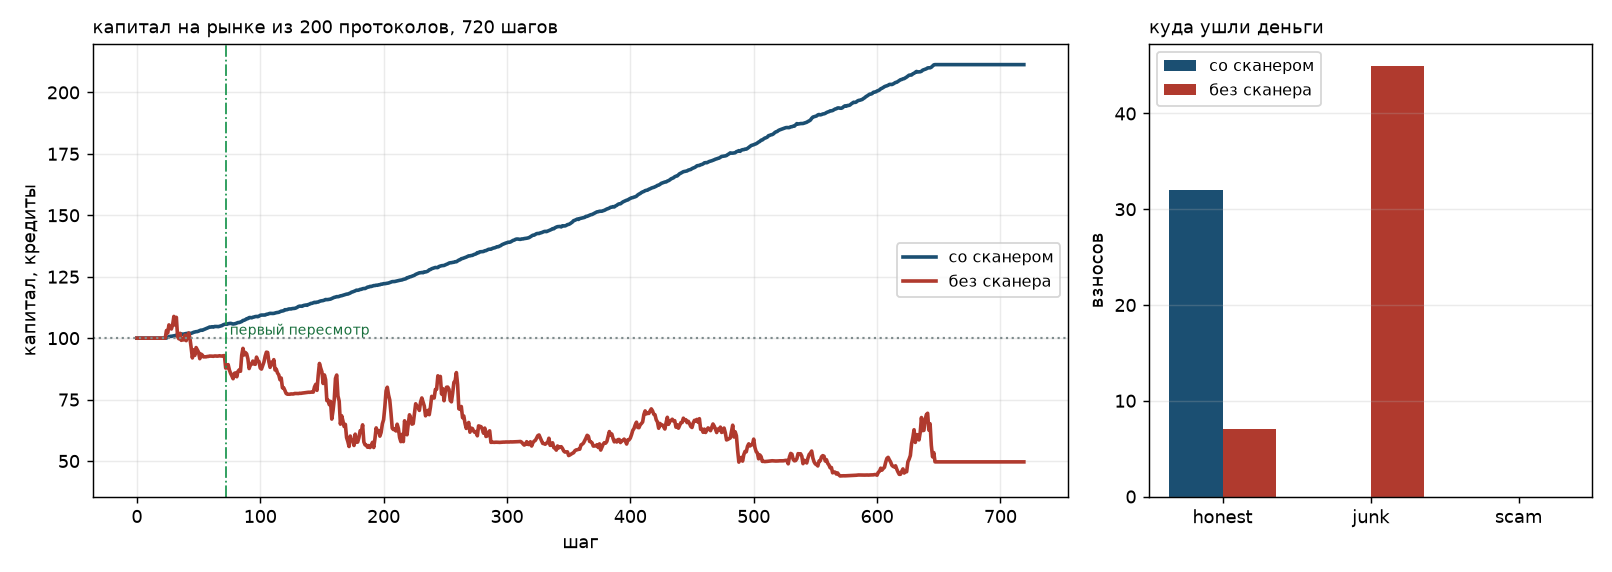

In [17]:
figure, (left, right) = plt.subplots(
    1, 2, figsize=(12.4, 4.4), gridspec_kw={"width_ratios": [2.2, 1.0]}
)

for label, arm, colour in (("со сканером", scanned, "#1b4f72"),
                           ("без сканера", naked, "#b03a2e")):
    path = np.array([row["equity"] for row in arm.trace])
    left.plot(np.arange(path.size), path, color=colour, linewidth=2.0, label=label)
left.axhline(P.START_CAPITAL, color="#7f8c8d", linestyle=":", linewidth=1.2)
left.axvline(REVIEW_AT, color="#229954", linestyle="-.", linewidth=1.0)
left.annotate(" первый пересмотр", xy=(REVIEW_AT, P.START_CAPITAL),
              fontsize=8, color="#196f3d", va="bottom")
left.set_xlabel("шаг")
left.set_ylabel("капитал, кредиты")
left.set_title("капитал на рынке из 200 протоколов, 720 шагов", fontsize=10, loc="left")
left.legend(fontsize=9)
left.grid(alpha=0.25)

kinds = [M.KIND_HONEST, M.KIND_JUNK, M.KIND_SCAM]
counted = {"со сканером": deposits_by_kind(scanned, scanned_market)[0],
           "без сканера": deposits_by_kind(naked, naked_market)[0]}
width = 0.36
places = np.arange(len(kinds))
right.bar(places - width / 2, [counted["со сканером"][kind] for kind in kinds],
          width, color="#1b4f72", label="со сканером")
right.bar(places + width / 2, [counted["без сканера"][kind] for kind in kinds],
          width, color="#b03a2e", label="без сканера")
right.set_xticks(places, kinds)
right.set_ylabel("взносов")
right.set_title("куда ушли деньги", fontsize=10, loc="left")
right.legend(fontsize=9)
right.grid(axis="y", alpha=0.25)

figure.tight_layout()
balance_png = "discovery_balance.png"
figure.savefig(balance_png, dpi=130)
plt.close(figure)
print("рисунок:", balance_png)
Image(filename=balance_png)


Что читается на двух картинках.

**Слева** две линии расходятся с шага 72, то есть ровно с первого пересмотра, и
расходятся не из-за ума, а из-за того, кого они согласились читать. Со сканером
капитал к шагу 792 стоит на 211 кредитах: десять честных протоколов платят
примерно то, что обещают. Без сканера он падает до 50: мусорные протоколы
проходят вердикт — у шума широкий разброс, и обещание на нём не опровергается, —
получают капитал и забирают часть каждого взноса.

**Справа** — та же мысль по адресам: у сканированной руки все 32 взноса ушли в
честные (синий столбец слева), у наивной 45 из 52 — в мусор (красный столбец
посередине). Скамы не финансирует ни одна рука: их кривая слишком идеальна, и
Statement #87 ловит её без всякого сканера. Мусор — тот класс, для которого
сканера нет замены: он не мошенник, он просто не доходность, и увидеть это можно
только арифметикой записи.

Отсюда и цена: сканер превращает пересмотр из «прочитать двести» в «прочитать
восемьдесят», а исполнение — из «одобрить всё, что прошло вердикт» в «десять
адресов, отобранных по силе записи».


## 10. Дикая природа: 200 пулов, которых никто не рисовал

До этой точки рынок был **нарисован**: `market_generator` и `ProtocolMarket.mock`
воспроизводятся до последнего float — именно поэтому на них можно откалибровать порог.
Но у нарисованного рынка есть предел: он не может удивить. Агент, который видел только
свой генератор, проверен только против своих же допущений.

`agent/physics/defillama_adapter.py` подключает **тот же шов** к живому API
(`https://yields.llama.fi`) и не меняет ни одного правила. Меняется только то, откуда
берутся числа:

| что публикует DeFiLlama | во что это превращается | почему именно так |
|---|---|---|
| `pool` (uuid) | `0x…` = SHA-256 от имени (`sim_address`) | у пула нет EVM-адреса; адрес должен быть стабильным и доказуемо **не** кошельком |
| `apy` (проценты в год, за день) | ставка за шаг `(1+apy)^(1/365)−1` | запись в этом слое — то, что компаундится; `annualise` возвращает ровно обещанное |
| `tvlUsd` | `turnover` — глубина пула в долларах | выход есть там, где есть глубина; порог сканера — `MIN_TVL_USD` = 1 млн |
| `apy: null` / `NaN` | **пропуск**, а не ноль и не вчерашнее число | заполненная точка — число, которого рынок не публиковал; доля пропусков печатается |
| `project`, `chain`, `symbol` | имя пула и строки таблицы | у площадки нет «тикера протокола», а таблице нужны человеческие подписи |

Три вещи, которые адаптер обязан делать на живом фиде и не должен на нарисованном:

* **не падать.** `get_top_pools` бросает одно *предложение* (`DefiLlamaUnavailable`),
  `fetch_pool_history` на битом uuid возвращает пустой кортеж, а движок на мёртвом фиде
  отдаёт пустую воронку с причиной в `error` — без стектрейса;
* **не выдумывать.** Пустая история не заполняется, короткая не растягивается,
  отсутствующий APY не становится нулём;
* **не ходить в сеть дважды.** Каталог (1.4 МБ) и каждая история кэшируются в
  `.cache/defillama` на шесть часов: второй прогон ноутбука меряет **тот же** рынок,
  а не соседний.


In [18]:
# Кэш — общий с CLI: иначе второй прогон ноутбука снова тянет 200 запросов.
import os
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.environ.setdefault("ENRG_CACHE_DIR", str(ROOT / ".cache"))

# Один переключатель: True — живые пулы DeFiLlama, False — нарисованный рынок.
REAL_MARKET = True

LIVE_LIMIT = 200             # сколько пулов просить у площадки
WATCH_ALL = True             # читать глубоко все 200, а не 128: без тела оценка стоит мс

if REAL_MARKET:
    engine = LL.DiscoveryEngine(
        mode=LL.MODE_REAL,
        scanner=LL.DefiLlamaScanner(timeout=60.0),   # таймаут явный: фид бывает медленным
        watch_limit=LIVE_LIMIT if WATCH_ALL else LL.WATCH_LIMIT,
    )
    live = engine.run(LIVE_LIMIT)
    if live.error:                                   # сеть — не обязанность ноутбука
        print("живой фид недоступен:", live.error)
        print("показываю тот же цикл на нарисованном рынке\n")
        live = LL.DiscoveryEngine(mode=LL.MODE_SYNTHETIC).run(LIVE_LIMIT)
else:
    live = LL.DiscoveryEngine(mode=LL.MODE_SYNTHETIC).run(LIVE_LIMIT)

print(live.summary_text())
print()
print(f"просканировано пулов     : {live.scanned}")
print(f"прочитано как записи     : {live.market}  (не прочитано: {len(live.skipped)})")
print(f"отсеяно сканером (ур. 1) : {len(live.watchlist.dropped)}")
print(f"отсеяно Entrain (ур. 2)  : {len(live.refused())}")
print(f"не измерено (UNMEASURED) : {live.unmeasured}")
print(f"одобрено к инвестициям   : {live.approved}")
print(f"время скана              : {live.elapsed:.1f} s")
if live.warnings:
    print(f"замечаний фида           : {len(live.warnings)}, первое: {live.warnings[0]}")


mode real_defillama: the venue (defillama) publishes 200 pools, 195 of them readable
  level 1 (scanner): kept 152, dropped 43 (noise, not a yield 36, record too short 7)
  level 2 (entrain): judged 83, refused 31, unmeasured 69 (HONEST 52, SUSPECT 31, UNMEASURED 69)
  approved for investment: 52 of 152

просканировано пулов     : 200
прочитано как записи     : 195  (не прочитано: 5)
отсеяно сканером (ур. 1) : 43
отсеяно Entrain (ур. 2)  : 31
не измерено (UNMEASURED) : 69
одобрено к инвестициям   : 52
время скана              : 0.9 s


### Воронка на живом рынке: три числа, которые нельзя складывать

**Уровень 1** отбрасывает то, что видно арифметике: пул без выхода (глубина меньше
миллиона), запись короче восьми точек, `CV` выше потолка — шум, а не доходность. Стоит
это микросекунды на пул.

**Уровень 2** — суждение о кривой: `A²` и `CV` (Statement #87) и обещание против записи.
Здесь и происходит главное на реальном рынке. Живые пулы почти никогда не бывают
«мусором» — они бывают **слишком ровными** (тридцать процентов годовых, которые вчера были
тридцатью, позавчера тридцатью и месяц назад тридцатью, — это не доходность с шумом, это
формула) или **слишком щедрыми на словах** (`APY` в каталоге выше того, что платит
собственная история пула на десяток стандартных ошибок). Первое ловит рука Statement #87,
второе — рука обещания.

Какая из двух сработает — это **вопрос к рынку, а не к настройке**, поэтому ячейка ниже
печатает обе величины: минимум и медиану `A²` против порога `STERILE_A2` и число пулов,
чью запись обогнало их же обещание. На снимке, который здесь получился, стерильных записей
не оказалось вовсе: реальные APY шумят слишком сильно, чтобы пройти под `0.1`, — и это
результат измерения, а не решение подкрутить порог.

**`UNMEASURED` — не отказ.** Дневная история моложе примерно десяти месяцев не даёт
четырёх окон по 128 точек с шагом 64, а без четырёх окон нет опроса: «ещё не читал» и
«это ложь» — разные предложения, и в отчёте они стоят в разных полях.

Текст причины печатает ядро (`risk_assessment._claim_reason`) и округляет проценты до
целых, поэтому в таблице рядом с ним стоят точные «обещает» и «по записи»: расхождение в
целых процентах — это округление, а расхождение в σ — это измерение.


In [19]:
def pool_row(row):
    """Одна строка отчёта: что обещано, что измерено и почему отказано."""
    return {
        "пул": row["name"],
        "чейн": row["chain"],
        "глубина, $млн": round(row["tvl_usd"] / 1e6, 1),
        "обещает APY": f"{row['apy']:.2f}%",
        "по записи": "—" if row["implied_apy"] is None else f"{row['implied_apy']:.2f}%",
        "A²": "—" if row["a2"] is None else f"{row['a2']:.3f}",
        "CV": "—" if row["cv"] is None else f"{row['cv']:.5f}",
        "σ обещания": "—" if row["claim_z"] is None else f"{row['claim_z']:.1f}",
        "окон": row["windows"],
        "вердикт": row["verdict"],
    }

rejected = live.top_rejected(5)
print(f"Отклонено, несмотря на обещанный APY — топ-{len(rejected)} по обещанию:")
display(pd.DataFrame([{**pool_row(row), "почему": row["reason"]} for row in rejected]))

rows = []
for name in live.approved_names():
    item = live.assessments[name]
    pool = live.pools.get(name)
    rows.append({
        "пул": name,
        "чейн": "" if pool is None else pool.chain,
        "глубина, $млн": 0.0 if pool is None else round(pool.tvl_usd / 1e6, 1),
        "обещает APY": f"{item.claim_apy:.2%}",
        "по записи": f"{item.implied_apy:.2%}",
        "A²": f"{item.a2:.2f}",
        "CV": f"{item.cv:.4f}",
        "точек": item.points,
    })
print(f"Одобрено к инвестициям: {len(rows)} пулов (HONEST — это вердикт о записи, не ордер)")
display(pd.DataFrame(rows))

# Две руки оценки, и какая из них сработала — это вопрос к рынку, а не к настройке.
a2 = [item.a2 for item in live.assessments.values() if item.a2 == item.a2]
cv = [item.cv for item in live.assessments.values() if item.cv == item.cv]
if a2:
    print(f"A² измеренных пулов : мин {min(a2):.2f}, медиана {statistics.median(a2):.2f}, "
          f"макс {max(a2):.1f} — порог стерильности {R.STERILE_A2}")
    print(f"CV измеренных пулов : мин {min(cv):.5f} — порог {R.STERILE_CV}")
print(f"стерильных записей   : {sum(1 for i in live.assessments.values() if i.sterile)} "
      f"(рука Statement #87)")
print(f"обещание выше записи : {sum(1 for i in live.assessments.values() if i.inflated)} "
      f"(на >{R.CLAIM_Z:.0f} σ — рука обещания)")
print(f"повторяющихся записей: {sum(1 for i in live.assessments.values() if i.repeat)} "
      f"(без тела структурная рука слепа — details['measured'] это говорит)")


Отклонено, несмотря на обещанный APY — топ-5 по обещанию:


,пул,чейн,"глубина, $млн",обещает APY,по записи,A²,CV,σ обещания,окон,вердикт,почему
0,uniswap-v3 WETH-USDC (Base),Base,154.7,75.17%,55.89%,9.056,0.65246,4.8,13,SUSPECT,claims 75% while its own record pays 56%: 4.8 ...
1,fluid-lite ETH (Ethereum),Ethereum,165.1,12.20%,5.00%,66.980,0.50518,37.7,20,SUSPECT,claims 12% while its own record pays 5%: 37.7 ...
2,reservoir-protocol WSRUSD (Ethereum),Ethereum,123.1,6.25%,5.70%,39.395,0.30479,10.6,5,SUSPECT,claims 6% while its own record pays 6%: 10.6 s...
3,aave-v3 USDT (Ethereum),Ethereum,116.3,5.87%,3.55%,112.846,0.76297,33.5,20,SUSPECT,claims 6% while its own record pays 4%: 33.5 s...
4,marinade-liquid-staking MSOL (Solana),Solana,214.7,5.48%,5.23%,9.455,0.21689,3.8,8,SUSPECT,claims 5% while its own record pays 5%: 3.8 st...


Одобрено к инвестициям: 52 пулов (HONEST — это вердикт о записи, не ордер)


,пул,чейн,"глубина, $млн",обещает APY,по записи,A²,CV,точек
0,binance-staked-sol BNSOL (Solana),Solana,1034.4,4.54%,4.60%,4.10,0.1021,618
1,jito-liquid-staking JITOSOL (Solana),Solana,983.7,4.79%,4.88%,8.40,0.1671,590
2,bybit-staked-sol BBSOL (Solana),Solana,140.4,4.67%,4.84%,14.41,0.1674,592
3,jupiter-staked-sol JUPSOL (Solana),Solana,482.4,5.01%,5.42%,17.28,0.1735,618
4,drift-staked-sol DSOL (Solana),Solana,269.3,4.93%,5.08%,9.24,0.1767,597
5,binance-staked-eth WBETH (BSC),BSC,506.8,2.19%,2.30%,50.50,0.2046,1239
6,binance-staked-eth WBETH (Ethereum),Ethereum,8781.0,2.19%,2.30%,50.50,0.2046,1239
7,morpho-blue SENPYUSDMAIN (Ethereum),Ethereum,356.8,5.35%,5.75%,22.30,0.2356,322
8,coinbase-wrapped-staked-eth CBETH (Ethereum),Ethereum,473.0,2.28%,2.41%,101.10,0.2789,1389
9,maple USDT (Ethereum),Ethereum,672.9,4.92%,4.84%,33.16,0.3039,466


A² измеренных пулов : мин 1.29, медиана 30.71, макс 465.6 — порог стерильности 0.1
CV измеренных пулов : мин 0.01528 — порог 0.005
стерильных записей   : 0 (рука Statement #87)
обещание выше записи : 72 (на >3 σ — рука обещания)
повторяющихся записей: 0 (без тела структурная рука слепа — details['measured'] это говорит)


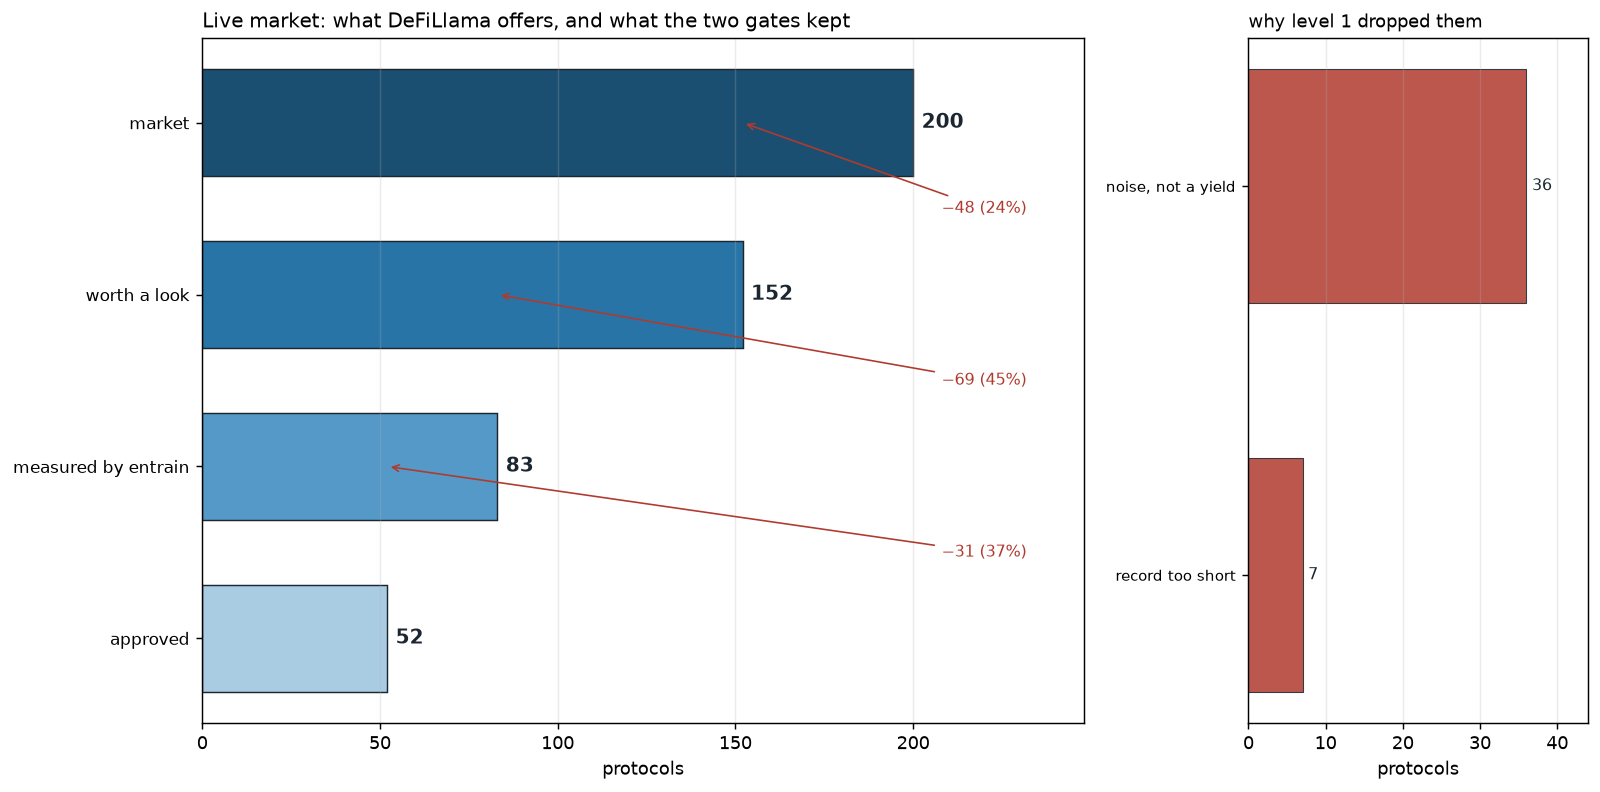

In [20]:
real_png = plot_funnel(
    live.stages(),
    "discovery_funnel_real.png",
    reasons=live.watchlist.reasons(),
    title="Live market: what DeFiLlama offers, and what the two gates kept",
)
Image(filename=str(real_png))


### Чего эти числа не значат

* **это не рекомендация и не ордер.** `HONEST` — вердикт о записи. Между «кривая похожа
  на настоящую» и «в этот пул стоит завести десятую часть империи» лежат книга
  (`Portfolio`), контрагент, смарт-контракт и решение оператора. Ни одной транзакции этот
  раздел не делает, и у движка нет метода, который её умеет;
* **`APY` — обещание площадки, а не выплата.** `claim_apy` берётся из строки каталога,
  запись — из истории. Именно расхождение между ними и даёт `SUSPECT`;
* **это снимок, а не жизнь.** Один запуск — один день рынка; второй запуск через неделю
  даст другие числа, и это не нестабильность измерения, это рынок;
* **пулы не одинаково свежие.** `step` площадки — длина самой длинной записи; короткая не
  растягивается, поэтому у молодых пулов `UNMEASURED` — норма, а не приговор;
* **прочитано ровно то, что публикуется.** Если площадка не отдала историю, пул попадает
  в `skipped` с причиной: отчёт, который молчит о своём охвате, врёт о полноте.


## 11. Охота за альфой: паника — это цена, а ложь — это формула

Воронка из раздела 10 отвечает на вопрос о **протоколе**: честная ли у него запись. Она
ничего не говорит о **дне**. Честный протокол тоже переживает плохую неделю: ликвидность
уходит, та же доходность делится на меньшее число долларов, и APY на графике площадки
вырастает втрое. Доходность выросла не потому, что протокол соврал, а потому, что выросла
премия за риск. `agent/physics/volatility_hunter.py` спрашивает ровно об этом: **запись всё
ещё выглядит как рынок, а цена — как страх?**

### Детектор, который не работает

«Текущий APY больше медианы на два сигма» — это четыре строки numpy. На том же живом скане
двухсот пулов его самая громкая находка выглядит так:

| пул | z (сырой) | APY покоя → сейчас | глубина |
|---|---|---|---|
| `blackrock-buidl BUIDL (BSC)` | **19.70 σ** | 3.22 % → 3.90 % | +25 % |

Токенизированный казначейский вексель — самый «панический» актив в DeFi. Это не ошибка
арифметики: ставка BUIDL меняется ступенькой при роллировании бумаги, MAD её ряда — сотые
доли пункта, и шаг в семь базисных пунктов оказывается «девятнадцатью сигмами». Поэтому в
детекторе два пола, и оба — часть аргумента:

* **пол в деньгах.** Дислокация не измеряется мельче, чем `PANIC_SIGMA_FLOOR` (0.25 п.п.), и
  не считается, если разрыв меньше `PANIC_GAP_PP` (1 п.п.) или меньше `PANIC_GAP_RATIO`
  (1.25×) от уровня покоя. Тот же BUIDL с полами читается как **2.63 σ / 0.66 п.п. /
  1.20×** — «вексель шагнул вслед за ФРС», и ничего больше;
* **пол в записи.** Кривая без рыночного шума — это обещание (Statement #87), и вторая рука
  проверяет его на **двух горизонтах**: вся история (`A²`, `CV`) и сам поднявшийся отрезок
  (`CV`). Пул может год шуметь как рынок, а потом **объявить** 300 % на две недели — и
  именно эти две недели стратегия и покупала бы.

### Две руки и один вывод

| рука | что измеряет | отказы |
|---|---|---|
| **цена** (`dislocation`) | последние 14 дней против уровня покоя: `z`, п.п., кратность и **отток глубины** | `CALM`, `GROWTH` |
| **запись** (`organic`) | Statement #87 на всей истории и на поднявшемся отрезке + вердикт оценки «в покое» | `FORMULA`, `DISHONEST` |

Только обе руки вместе — `PANIC`, по той же причине, что и у ядра: цена сама по себе не
говорит, настоящий ли протокол, а запись сама по себе не говорит, отличается ли сегодняшний
день от вчерашнего. Плюс одна тонкость, без которой детектор отказывал бы **каждой** панике:
пул судится по **уровню покоя** (`resting_claim` — медиана всего, что было до последних двух
недель), а не по той ставке, которую паника рекламирует. Вопрос звучит «честен ли протокол,
когда спокоен», и паника не имеет права расширять потолок, по которому её судят.


In [21]:
# Тот же сканер и тот же кэш, что у воронки: живой скан не стоит ни одного нового запроса.
alpha_scanner = LL.DefiLlamaScanner(timeout=60.0)
hunter = VH.VolatilityHunter(scanner=alpha_scanner)
today = hunter.scan(live)

print(today.summary_text())
print()


def depth_word(exodus):
    """Отток глубины человеческим языком: проценты, а не «+3465 %» на пуле с нулём."""
    if exodus != exodus or abs(exodus) >= 10:
        return "×" + ("∞" if exodus == exodus and exodus > 0 else "0")
    return f"{exodus:+.0%}"


rising = [s for s in today.signals if s.dislocation.gap_pp > 0.05]
print(f"пулов, поднявших ставку больше чем на 0.05 п.п.: {len(rising)} из {len(today.signals)}")
if rising:
    table = pd.DataFrame([{
        "пул": s.name[:34],
        "покой, %": round(s.dislocation.resting, 2),
        "сейчас, %": round(s.dislocation.recent, 2),
        "разрыв, п.п.": round(s.dislocation.gap_pp, 2),
        "z": round(s.dislocation.z, 2),
        "глубина": depth_word(s.dislocation.exodus),
        "A²": round(s.organic.a2, 1),
        "CV": round(s.organic.cv, 2),
        "вердикт": s.verdict,
    } for s in sorted(rising, key=lambda s: -s.dislocation.gap_pp)[:8]])
    print(table.to_string(index=False))
print()
print("сегодняшняя паника:", ", ".join(s.name for s in today.panics()) or "нет ни одной")


venue defillama: 52 approved pools read, 52 measured
  verdicts: CALM 52
  panics: 0

пулов, поднявших ставку больше чем на 0.05 п.п.: 1 из 52
                  пул  покой, %  сейчас, %  разрыв, п.п.    z глубина   A²  CV вердикт
maple USDT (Ethereum)       4.7       4.95          0.26 0.25    -31% 33.2 0.3    CALM

сегодняшняя паника: нет ни одной


### Та же арифметика, но по каждому дню истории

Живой скан — это один день. Чтобы увидеть, работает ли детектор вообще, ему задают тот же
вопрос про **каждый прошлый день каждого пула**: `PanicDetector.replay` берёт `apy[:day+1]`,
то есть ровно те числа, которые были у агента в тот день, и ничего больше (это проверяет
тест, а не слово). Только после вердикта к нему приклеивается колонка будущего — медиана APY
за следующие 30 дней, — и она отвечает на единственный вопрос, который стоит задавать
бэктесту:

**пул платил в панике больше, чем платил в покое?**

`paid_pp` — это `вперёд − покой`, в пунктах. Плюс означает, что поднятая ставка дожила до
следующего месяца; минус — что рынок был прав, а охотник опоздал. Минусы печатаются с тем же
весом, что и плюсы.

И контроль, без которого любые плюсы ничего не стоят: **те же пулы, обычные дни**. Каждый
тридцатый день той же истории, та же статистика. Если у обычных дней медиана тоже
положительная, то «альфа» — это дрейф доходности, а не паника.


In [22]:
def replay_market(rows, forward=30):
    """Каждая паника каждого пула — с честной колонкой будущего."""
    events = []
    for row in rows:
        frame = alpha_scanner.fetch_pool_frame(row.uuid)
        if len(frame) < VH.PANIC_MIN_POINTS + forward + VH.PANIC_RECENT:
            continue
        events.extend(
            hunter.detector.replay(frame.apy, frame.tvl, name=row.name, forward=forward)
        )
    return events


def null_days(rows, forward=30, stride=30):
    """Те же пулы, обычные дни: контрольная выборка для paid_pp."""
    values = []
    for row in rows:
        frame = alpha_scanner.fetch_pool_frame(row.uuid)
        apy = np.asarray(frame.apy, dtype=float)
        for day in range(VH.PANIC_MIN_POINTS, len(apy) - forward, stride):
            rest = VH.resting_claim(apy[: day + 1])
            fwd = VH.forward_apy(apy, day, forward)
            if not math.isnan(fwd):
                values.append(fwd - rest)
    return values


live_pools = alpha_scanner.get_top_pools(200)
panic_events = replay_market(live_pools)
ordinary = null_days(live_pools)

paid = [e.paid_pp for e in panic_events if not math.isnan(e.paid_pp)]
print(f"паник найдено               : {len(panic_events)} у {len({e.signal.name for e in panic_events})} пулов из {len(live_pools)}")
print(f"дожили до следующего месяца : {sum(1 for p in paid if p > 0)} из {len(paid)}")
print(f"медиана paid_pp (паника)    : {statistics.median(paid):+.3f} п.п.")
print(f"медиана paid_pp (обычный день): {statistics.median(ordinary):+.3f} п.п.  (дней: {len(ordinary)})")
print()
biggest = sorted(panic_events, key=lambda e: -abs(e.paid_pp))[:8]
table = pd.DataFrame([{
    "пул": e.signal.name[:34],
    "день": e.day,
    "покой, %": round(e.resting_apy, 2),
    "паника, %": round(e.signal.dislocation.recent, 2),
    "z": round(e.signal.dislocation.z, 2),
    "глубина": f"{e.signal.dislocation.exodus:+.0%}",
    "уверенность": round(e.signal.confidence, 2),
    "вперёд, %": round(e.forward_apy, 2),
    "paid, п.п.": round(e.paid_pp, 2),
} for e in biggest])
print(table.to_string(index=False))


паник найдено               : 53 у 17 пулов из 200
дожили до следующего месяца : 41 из 53
медиана paid_pp (паника)    : +1.350 п.п.
медиана paid_pp (обычный день): -0.004 п.п.  (дней: 3142)

                        пул  день  покой, %  паника, %     z глубина  уверенность  вперёд, %  paid, п.п.
 venus-core-pool WBNB (BSC)   533      0.46      17.51 37.66    -43%         0.94      34.83       34.37
sky-lending SDAI (Ethereum)   740      5.00      11.50  2.19    -25%         0.46      11.50        6.50
 venus-core-pool WBNB (BSC)   380      0.47       2.22  4.40    -44%         0.74       4.85        4.38
 venus-core-pool WBNB (BSC)   650      0.53      27.62 40.29    -59%         1.00       4.70        4.17
 venus-core-pool WBNB (BSC)   596      0.52      24.60 39.72    -57%         1.00       4.58        4.06
    aave-v3 USDE (Ethereum)   183      3.24       7.77  2.89    -78%         0.82       7.26        4.03
      aave-v3 USDE (Plasma)   239      1.18       5.22  9.34    -48%      

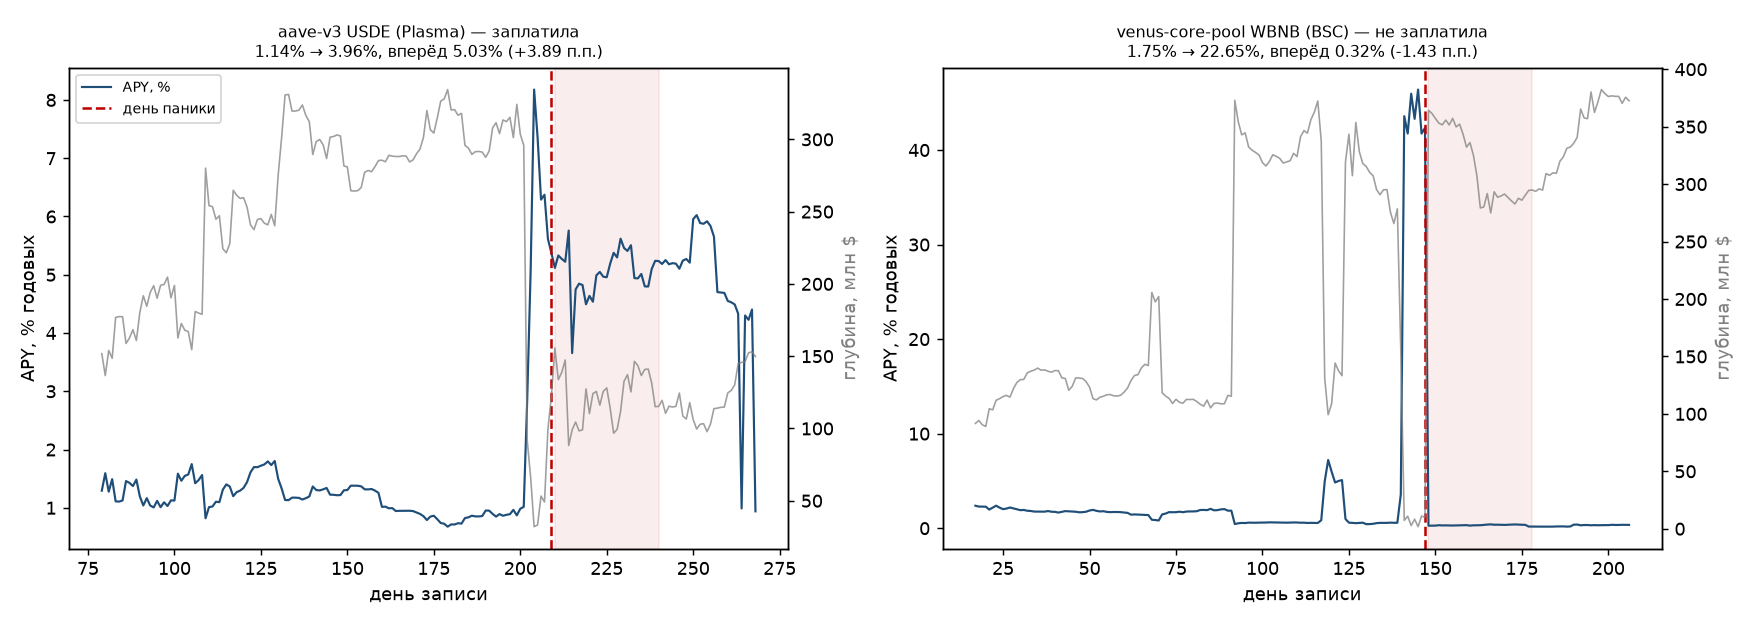

In [23]:
# Две паники одного и того же детектора: одна заплатила, вторая — нет. Выбор сделан ПОСЛЕ
# прогона (это иллюстрация, а не выборка), а все числа в заголовках считаются здесь же.
def episode_for(name):
    for event in panic_events:
        if event.signal.name == name:
            return event
    return max(panic_events, key=lambda e: e.paid_pp)


by_name = {row.name: row for row in live_pools}
paid_episode = episode_for("aave-v3 USDE (Plasma)")
faded_episode = episode_for("venus-core-pool WBNB (BSC)")

figure, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
for axis, event, label in (
    (axes[0], paid_episode, "заплатила"),
    (axes[1], faded_episode, "не заплатила"),
):
    series = alpha_scanner.fetch_pool_frame(by_name[event.signal.name].uuid)
    apy = np.asarray(series.apy, dtype=float)
    depth = np.asarray(series.tvl, dtype=float) / 1e6
    lo, hi = max(event.day - 130, 0), min(event.day + 60, len(apy))
    days = np.arange(lo, hi)
    axis.plot(days, apy[lo:hi], color="#1f4e79", linewidth=1.2, label="APY, %")
    axis.axvline(event.day, color="#c00000", linestyle="--", linewidth=1.4, label="день паники")
    axis.axvspan(event.day + 1, min(event.day + 31, hi - 1), color="#c00000", alpha=0.07)
    axis.set_xlabel("день записи")
    axis.set_ylabel("APY, % годовых")
    twin = axis.twinx()
    twin.plot(days, depth[lo:hi], color="#7f7f7f", linewidth=0.9, alpha=0.75)
    twin.set_ylabel("глубина, млн $", color="#7f7f7f")
    axis.set_title(
        f"{event.signal.name[:34]} — {label}\n"
        f"{event.resting_apy:.2f}% → {event.signal.dislocation.recent:.2f}%, "
        f"вперёд {event.forward_apy:.2f}% ({event.paid_pp:+.2f} п.п.)",
        fontsize=9,
    )
axes[0].legend(loc="upper left", fontsize=8)
figure.tight_layout()
figure.savefig("panic_replay.png", dpi=130)
plt.close(figure)
Image(filename="panic_replay.png")


In [24]:
def book_over(event, *, boost, forward=30, capital=100.0):
    """Одна и та же книга на одном и том же окне: разница только в весе."""
    series = alpha_scanner.fetch_pool_frame(by_name[event.signal.name].uuid)
    protocol = P.Protocol(
        name=event.signal.name,
        bucket=event.signal.bucket,
        claim_apy=float(event.signal.resting_apy),
        returns=LL.to_returns(series.apy),
        address=P.sim_address(event.signal.name),
        turnover=float(by_name[event.signal.name].tvl_usd),
    )
    wallet = P.Portfolio(whitelist=P.WhiteList((protocol.address,)), cash=capital)
    wallet.approve([protocol])
    targets = wallet.boosted_targets([event.signal], step=event.day) if boost else None
    wallet.rebalance(
        {"safe": protocol, "active": None, "experimental": None},
        step=event.day,
        targets=targets,
    )
    for step in range(event.day + 1, event.day + 1 + forward):
        wallet.accrue(step)
    return wallet, protocol, targets


plain, tracked, _ = book_over(paid_episode, boost=False)
hunting, _, targets = book_over(paid_episode, boost=True)


def line(tag, wallet):
    placed = wallet.value(tracked.address)
    print(f"{tag:<10} в пуле {placed:7.2f} кр.  наличные {wallet.cash:7.2f}  "
          f"капитал {wallet.equity:8.4f}")


print(f"паника: {paid_episode.signal.name}  день {paid_episode.day}  "
      f"уверенность {paid_episode.signal.confidence:.2f}")
print(f"вес по сигналу    : {hunting.alpha_log[0]['weight']:.3f}× ведра "
      f"(потолок {1 + P.ALPHA_BOOST_CAP:.2f}×)")
print(f"цели              : " + ", ".join(f"{k} {v:.3f}" for k, v in targets.items()))
print(f"запись в журнале  : {hunting.alpha_log[0]}")
print()
line("без веса", plain)
line("с весом", hunting)
extra = hunting.equity - plain.equity
moved = hunting.value(tracked.address) - plain.value(tracked.address)
print()
print(f"добавлено капитала: {moved:.2f} кр.; заработано сверх: {extra:+.4f} кр. "
      f"за 30 дней ({100 * extra / max(moved, 1e-9):.2f}% на добавленный капитал)")
print(f"наличные с весом  : {100 * hunting.cash / hunting.equity:.1f}% "
      f"(пол {100 * P.ALPHA_CASH_FLOOR:.0f}%)")

faded_plain, faded_tracked, _ = book_over(faded_episode, boost=False)
faded_boost, _, faded_targets = book_over(faded_episode, boost=True)
faded_extra = faded_boost.equity - faded_plain.equity
print()
print(f"а паника, которая не дожила ({faded_episode.signal.name[:30]}, "
      f"paid {faded_episode.paid_pp:+.2f} п.п.), всё равно принесла "
      f"{faded_extra:+.4f} кр.: ставка не ушла ниже уровня покоя — "
      "и это ровно то, почему дисциплина живёт в сигнале, а не в размере")


паника: aave-v3 USDE (Plasma)  день 209  уверенность 0.97
вес по сигналу    : 1.486× ведра (потолок 1.50×)
цели              : safe 0.891, active 0.300, experimental 0.100
запись в журнале  : {'step': 209, 'bucket': 'safe', 'protocol': 'aave-v3 USDE (Plasma)', 'confidence': 0.971, 'weight': 1.4855, 'wanted': 0.291291, 'granted': 0.291291, 'capacity_left': 0.658709}

без веса   в пуле   60.24 кр.  наличные   40.00  капитал 100.2428
с весом    в пуле   89.49 кр.  наличные   10.87  капитал 100.3606

добавлено капитала: 29.25 кр.; заработано сверх: +0.1179 кр. за 30 дней (0.40% на добавленный капитал)
наличные с весом  : 10.8% (пол 5%)

а паника, которая не дожила (venus-core-pool WBNB (BSC), paid -1.43 п.п.), всё равно принесла +0.0068 кр.: ставка не ушла ниже уровня покоя — и это ровно то, почему дисциплина живёт в сигнале, а не в размере


### Чего эта стратегия не умеет

* **это не торговля страхом, а отказ от него.** Сигнал говорит «протокол честен, а цена
  сошла с ума»; он не говорит «протокол выздоровеет». Паника, которая не дожила до
  следующего месяца (`paid_pp < 0`), в таблице выше есть, и она там не для красоты;
* **у книги нет издержек.** В этой модели нет газа, проскальзывания и комиссии — это
  заявленное свойство `Portfolio`, а не забывчивость. Добавочный капитал заработал столько
  процентов, сколько заплатил пул; любой оборот, который стоит дороже этой цифры, съест всю
  альфу. Настоящая книга обязана считать это до того, как двигать кредиты;
* **вес ограничен политикой, а не уверенностью.** `ALPHA_BOOST_CAP` — половина ведра, и он
  ограничивает **одно измерение**. Когда свободных наличных нет, книга не покупает панику
  вообще (`ALPHA_CASH_FLOOR`): единственный капитал, который может ответить на неожиданность,
  — это неинвестированный;
* **глубина — это обещание выхода, а не выход.** `tvlUsd` показывает, сколько в пуле лежит;
  он не показывает, сколько оттуда можно вынести, не сдвинув ставку. Отток глубины — признак
  паники и одновременно напоминание, что выходить будет так же тесно;
* **это снимок одного дня и одной истории.** У живого скана сегодня ноль паник — это ответ, а
  не пустой экран: рынок в этот день не истекал кровью. Ответ «паники нет» стоит дороже, чем
  «купил, потому что z большой».


## 12. Чего здесь нет

* **ни одного ключа.** Адреса — SHA-256 от имени; реальная площадка подключается только
  если оператор сам выставил `TESTNET_RPC_URL`, и без `TESTNET_PRIVATE_KEY` умеет
  только читать — ни одна строка этого ноутбука ничего не подписывает;
* **ни одного реального API — до раздела 10.** До него рынок целиком сгенерирован
  (`ProtocolMarket.mock`, `market_generator`): семь кривых, два изъятия, два краха —
  объявленные константы, а не найденные зависимости. Живой фид появляется только
  в разделе 10 (`REAL_MARKET = True`), только на чтение и только через адаптер;
* **ни одного «подкрученного» числа под историю.** Пороги (`STERILE_A2`, `STERILE_CV`,
  `KILL_DRAWDOWN` = 15 %, `REPEAT_R2`, `RESONANCE_FLOOR`) — политика, названная до
  прогона; что они делают — измерено в тестах (`tests/test_physics_portfolio.py`,
  `tests/test_physics_risk_assessment.py`);
* **одна жизнь — не распределение.** Как и в L3, здесь прожита одна жизнь на одном
  рынке: сид 7 у рынка, 11 у тела. Другой сид — другая жизнь, и утверждение этого
  ноутбука звучит как «на этом рынке с этими правилами получилось так».

* **рынок из 200 — нарисованный, а не найденный.** `market_generator` — это
  синтетика с известным ответом: сид и смесь воспроизводимы до последнего float, а
  `rug_step` и `note` агент не видит вовсе — иначе воронка была бы сортировкой по
  ответу, а не измерением;
* **воронка — два разных вопроса, а не один фильтр.** Сканер отбрасывает только то,
  что видно арифметике (мёртвое, короткое, без оборота, шум, убыток под обещанием),
  а суждение о кривой остаётся за Statement #87; десять адресов в
  `execution_whitelist` — это политика (потолок внимания), поэтому в отчёте `capped`
  лежит отдельно от `refused`;

Шов пройден до конца. Числа приходят не из `ProtocolMarket`, а из `IWeb3Provider`, и у
этого интерфейса теперь две реализации: `MockWeb3Provider` (объявленный рынок) и
`RealTestnetProvider` (`agent/physics/real_testnet_provider.py`) — Sepolia или локальный
Anvil, конфигурация только из окружения, `dry_run` перед каждой подписью и обязательное
ожидание квитанции. Переход в сеть — по-прежнему `provider =` в одной строке и ни одной
правки в оценке, потолке или рубильнике. Масштаб — тоже: `scanner =` в одной
строке меняет не правила, а объём чтения, и воронка это печатает.


In [25]:
checks = {}
start = empire.trace[0]["equity"]
end = empire.trace[-1]["equity"]
checks["капитал вырос"] = end > start
checks["каждый взнос прошёл через IWeb3Provider"] = stakes_by_empire == sum(
    1 for event in empire.portfolio.events if event["action"] == "deposit"
)
checks["обвинения отправлены провайдеру, а не забыты"] = (
    len(empire.proofs) > 0 and len(empire.proofs) == len(provider.proofs)
)
checks["ни один адрес вне белого списка не получил капитал"] = all(
    market.whitelist.allows(event["address"])
    for event in empire.portfolio.events if event["action"] == "deposit"
)
checks["ни одна позиция не открыта в протокол без вердикта HONEST"] = all(
    empire.assessments[decision["step"]][name]["verdict"] == R.HONEST
    for decision in empire.decisions
    for name in decision["plan"].values() if name is not None
)
checks["обе ловушки распознаны до своего изъятия"] = all(
    any(row[name]["verdict"] == R.SCAM_TRAP and step < P.TRAP_RUGS[name]
        for step, row in empire.assessments.items())
    for name in ("YieldMax", "AurumDAO")
)
checks["рубильник сработал на просадке"] = any(
    trigger.arm == R.ARM_DRAWDOWN for trigger in empire.kill_switch.triggers
)
checks["волатильность поймала смену режима"] = any(
    trigger.arm == R.ARM_VOLATILITY for trigger in empire.kill_switch.triggers
)
checks["империя закончила выше обеих наивных политик"] = end > max(
    investor.history()["equity"][-1] for _, investor in foils
)

# ── расширение вселенной: воронка, две руки и десять адресов ──────────────
checks["воронка сходится: 200 = 200 (все учтены)"] = funnel.market == (
    len(funnel.watchlist.dropped) + len(funnel.refused)
    + len(funnel.capped) + len(funnel.approved)
)
checks["воронка: 200 → 120 → 70 → 10"] = (
    funnel.market, len(funnel.watchlist.dropped), len(funnel.approved)
) == (200, 120, 10) and funnel.watched == 80 and (
    len(funnel.refused) + len(funnel.capped)
) == 70
checks["сканированием нельзя одобрить ни одного адреса"] = not any(
    hasattr(D.Scanner(), method)
    for method in ("approve", "whitelist", "execution_whitelist", "admit")
)
checks["десять одобренных — десять честных (ответ ключа)"] = (
    {M.kind_of(big.protocol(name)) for name in funnel.approved_names()}
    == {M.KIND_HONEST}
)
checks["со сканером капитал вырос, без сканера — упал"] = (
    scanned.trace[-1]["equity"] > scanned.trace[0]["equity"]
    and naked.trace[-1]["equity"] < naked.trace[0]["equity"]
)
checks["ни один скам и ни один мусор не получил кредита"] = (
    {kind for kind, count in deposits_by_kind(scanned, scanned_market)[0].items()
     if count} == {M.KIND_HONEST}
)
t0 = time.perf_counter()
M.generate_protocols(count=500, steps=STEPS, seed=SEED)
checks["500 протоколов рисуются быстрее секунды"] = (
    time.perf_counter() - t0
) < 1.0

# площадка, у которой есть узел и нет ключа: читать может, подписывать нет
read_only_venue = RealTestnetProvider(env={"TESTNET_RPC_URL": "http://127.0.0.1:8545"})
checks["реальная площадка отвечает IWeb3Provider и без ключа только читает"] = (
    isinstance(read_only_venue, IWeb3Provider) and read_only_venue.can_sign is False
)

# ── охота за альфой: сигнал, вес и то, чего не произошло ───────────────────
checks["охотник не умеет подписывать, стейкать и переводить"] = not any(
    hasattr(surface, method)
    for surface in (hunter, hunter.detector, today, hunter.detector.__class__)
    for method in ("execute_stake", "sign", "send", "transfer", "withdraw")
)
checks["вердикты живого скана складываются в прочитанное"] = (
    today.measured + len(today.unmeasured()) == today.scanned
)
checks["вес по сигналу не выше политики"] = (
    hunting.alpha_log[0]["weight"] <= 1.0 + P.ALPHA_BOOST_CAP + 1e-12
)
checks["с весом в пуле больше, а наличные не ниже пола"] = (
    hunting.value(tracked.address) > plain.value(tracked.address)
    and hunting.cash >= P.ALPHA_CASH_FLOOR * hunting.equity - 1e-9
)
checks["каждая паника прошла обе руки: запись органическая и честная в покое"] = all(
    event.signal.organic.organic and event.signal.resting_verdict == R.HONEST
    for event in panic_events
)
_prefix = alpha_scanner.fetch_pool_frame(by_name[paid_episode.signal.name].uuid)
checks["сигнал дня D воспроизводится по своему префиксу (будущего не видно)"] = abs(
    hunter.detector.measure(
        _prefix.apy[: paid_episode.day + 1],
        _prefix.tvl[: paid_episode.day + 1],
        name=paid_episode.signal.name,
    ).confidence
    - paid_episode.signal.confidence
) < 1e-12

for name, passed in checks.items():
    print(f"{'OK  ' if passed else 'FAIL'} {name}")
print("\nвсё правило пройдено:", all(checks.values()))


OK   капитал вырос
OK   каждый взнос прошёл через IWeb3Provider
OK   обвинения отправлены провайдеру, а не забыты
OK   ни один адрес вне белого списка не получил капитал
OK   ни одна позиция не открыта в протокол без вердикта HONEST
OK   обе ловушки распознаны до своего изъятия
OK   рубильник сработал на просадке
OK   волатильность поймала смену режима
OK   империя закончила выше обеих наивных политик
OK   воронка сходится: 200 = 200 (все учтены)
OK   воронка: 200 → 120 → 70 → 10
OK   сканированием нельзя одобрить ни одного адреса
OK   десять одобренных — десять честных (ответ ключа)
OK   со сканером капитал вырос, без сканера — упал
OK   ни один скам и ни один мусор не получил кредита
OK   500 протоколов рисуются быстрее секунды
OK   реальная площадка отвечает IWeb3Provider и без ключа только читает
OK   охотник не умеет подписывать, стейкать и переводить
OK   вердикты живого скана складываются в прочитанное
OK   вес по сигналу не выше политики
OK   с весом в пуле больше, а наличные н